# Modeling with RDKit descriptors and Morgan fingerprints

Same models, splits and CV as `03_Modeling.ipynb`, but with two other feature sets (both plus temperature `T`):
- **Descriptors**: `descriptor_cols` (TPSA, LogP, VSA bins, ...). Standardized.
- **Morgan**: `morgan_cols` (2048 binary bits). Only `T` is standardized, the bits are left as 0/1.

Results are saved in the same `metrics_<split>.pkl` files, with `description` = the feature set, so they can be compared with the group-contribution (`GC`) rows.

# Importing train/test datasets and building X, y

In [1]:
import pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.metrics import (mean_squared_error, mean_absolute_error, root_mean_squared_error,
                             r2_score)

SPLITS = ['Butina', 'Family']
TARGET = 'Surface_tension'

with open(r"Data and variables/ML_variables.pkl", "rb") as f:
    ml_vars = pickle.load(f)
descriptor_cols = ml_vars["descriptor_cols"]
morgan_cols = ml_vars["morgan_cols"]

# T is not part of either list, so it is appended
FEATURES = {
    'Descriptors': descriptor_cols + ['T'],
    'Morgan': morgan_cols + ['T'],
}
FSETS = list(FEATURES)

# Morgan searches are much more expensive (2049 features), so they get fewer random-search iterations
ITER_SCALE = {'Descriptors': 1.0, 'Morgan': 0.4}

# Same logic used in 02_ChemicalDataset to build each train/test split:
# StratifiedGroupKFold with groups=ChemID, stratified by Butina cluster or by chemical Family
STRAT_COL = {'Butina': 'cluster_id', 'Family': 'Family'}
GROUP_COL = 'ChemID'
N_CV = 5


def make_cv(train, split, n_splits=N_CV):
    """Explicit CV folds for the training set that preserve how the outer split was built:
    a compound (ChemID) never appears in two folds, and each fold keeps a similar cluster/family mix."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')     # singleton clusters/families can't be stratified
        folds = list(sgkf.split(train, y=train[STRAT_COL[split]], groups=train[GROUP_COL]))
    for tr, va in folds:
        assert set(train.iloc[tr][GROUP_COL]).isdisjoint(train.iloc[va][GROUP_COL])
    return folds


# data[(feature_set, split)] -> X_train, y_train, X_test, y_test and CV folds
# (the folds depend only on the split, so both feature sets share them)
data = {}
test_meta = {}   # split -> ChemID/Family/TC for the test rows (same rows for every feature set)
for s in SPLITS:
    train = pd.read_pickle(rf'Data and variables/train_{s}.pkl')
    test = pd.read_pickle(rf'Data and variables/test_{s}.pkl')
    cv = make_cv(train, s)
    test_meta[s] = test[['ChemID', 'Family', 'TC']]   # TC: post-hoc check only, never a model feature
    for fs, cols in FEATURES.items():
        data[(fs, s)] = dict(X_train=train[cols], y_train=train[TARGET],
                             X_test=test[cols], y_test=test[TARGET], cv=cv)

# the models cannot handle missing/infinite values
for (fs, s), d in data.items():
    for part in ('X_train', 'X_test'):
        bad = ~np.isfinite(d[part].to_numpy(dtype=float))
        assert not bad.any(), f"{fs}/{s}/{part}: NaN/inf in columns {list(d[part].columns[bad.any(axis=0)])}"
    print(fs, s, d['X_train'].shape, d['X_test'].shape)

# metrics tables (one per split, shared with 03_Modeling), fitted models and per-fold CV metrics
COLUMNS = ['description', 'algorithm', 'MSE', 'RMSE', 'MAE', 'SD_error', 'NRMSE_%', 'WAPE_%', 'r2_score']
metrics_paths = {s: rf'Data and variables/metrics_{s}.pkl' for s in SPLITS}
metrics = {}
for s in SPLITS:
    try:
        metrics[s] = pd.read_pickle(metrics_paths[s])
    except FileNotFoundError:
        metrics[s] = pd.DataFrame(columns=COLUMNS)

models = {}      # (algorithm, feature_set, split) -> fitted estimator
cv_folds = {}    # (algorithm, feature_set, split) -> per-fold validation metrics of the best candidate

Descriptors Butina (17058, 51) (8530, 51)
Morgan Butina (17058, 2049) (8530, 2049)
Descriptors Family (17101, 51) (8487, 51)
Morgan Family (17101, 2049) (8487, 2049)


# Helper functions

In [2]:
def get_metrics(model, X_test, y_test, metrics, path, model_desc, algorithm):
    """Evaluate on the test set, add/replace the row in `metrics`, save it and return it."""
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred
    rmse = root_mean_squared_error(y_test, y_pred)

    row = pd.DataFrame([{
        'description': model_desc,
        'algorithm': algorithm,
        'MSE': mean_squared_error(y_test, y_pred),
        'RMSE': rmse,
        'MAE': mean_absolute_error(y_test, y_pred),
        'SD_error': np.std(residuals, ddof=1),
        'NRMSE_%': rmse / np.mean(y_test) * 100,      # % of mean experimental value
        'WAPE_%': residuals.abs().sum() / y_test.abs().sum() * 100,  # weighted (not pointwise) absolute % error
        'r2_score': r2_score(y_test, y_pred),
    }])

    # re-running a model replaces its previous row
    keep = ~((metrics['description'] == model_desc) & (metrics['algorithm'] == algorithm))
    metrics = pd.concat([metrics[keep], row], ignore_index=True)
    metrics.to_pickle(path)
    return metrics


CV_SCORING = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error', 'r2': 'r2',
              'MSE': 'neg_mean_squared_error'}


def get_best(reg, params, X, y, cv, n_iter=50, n_jobs=-1):
    """Randomized search selecting on MSE. Returns (best estimator, per-fold metrics of the best candidate)."""
    rcv = RandomizedSearchCV(reg, params, n_iter=n_iter, cv=cv, scoring=CV_SCORING, refit='MSE',
                             random_state=42, n_jobs=n_jobs)
    rcv.fit(X, y)
    res, i = rcv.cv_results_, rcv.best_index_
    n_folds = rcv.n_splits_
    folds = pd.DataFrame({
        'fold': range(1, n_folds + 1),
        'n_val': [len(v) for _, v in cv],
        'RMSE': [-res[f'split{k}_test_RMSE'][i] for k in range(n_folds)],
        'MAE': [-res[f'split{k}_test_MAE'][i] for k in range(n_folds)],
        'r2': [res[f'split{k}_test_r2'][i] for k in range(n_folds)],
    }).set_index('fold')
    print('best params:', rcv.best_params_)
    return rcv.best_estimator_, folds


def show_folds(folds, title):
    summary = pd.DataFrame({'mean': folds[['RMSE', 'MAE', 'r2']].mean(), 'std': folds[['RMSE', 'MAE', 'r2']].std()}).T
    print(f'CV metrics per fold - {title}')
    display(pd.concat([folds, summary]).round(3))


def plot_actual_vs_predicted(model, X_test, y_test, title):
    y_pred = model.predict(X_test)
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, y_pred, alpha=0.5)
    mn, mx = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    plt.plot([mn, mx], [mn, mx], 'r--')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.text(0.05, 0.95, f'{title}\nR² = {r2_score(y_test, y_pred):.3f}',
             transform=plt.gca().transAxes, va='top', bbox=dict(facecolor='white', alpha=0.8))
    plt.show()


def make_scaler(fs):
    """Descriptors: standardize everything. Morgan: standardize T only, leave the 0/1 bits untouched
    (output order: T first, then the bits)."""
    if fs == 'Morgan':
        return ColumnTransformer([('T', StandardScaler(), ['T']),
                                  ('bits', 'passthrough', morgan_cols)],
                                 verbose_feature_names_out=False)
    return StandardScaler()


def scaled(est, scaler):
    """Scale X (fit on training folds only) and standardize y; predictions return in original units."""
    return TransformedTargetRegressor(regressor=make_pipeline(scaler, est), transformer=StandardScaler())


def record(model, algorithm, fs, split):
    d = data[(fs, split)]
    metrics[split] = get_metrics(model, d['X_test'], d['y_test'], metrics[split],
                                 metrics_paths[split], fs, algorithm)
    models[(algorithm, fs, split)] = model


def fit_all(algorithm, build, params, n_iter=50, plot=True, n_jobs=-1):
    """For every feature set and split: tune `build(scaler)` with randomized CV (grouped by ChemID,
    stratified like the split), evaluate on the test set and store the results.
    `params` can be a dict or a function of the feature set."""
    for fs in FSETS:
        for s in SPLITS:
            print(f'--- {algorithm} | {fs} | {s} split ---')
            d = data[(fs, s)]
            p = params(fs) if callable(params) else params
            best, folds = get_best(build(make_scaler(fs)), p, d['X_train'], d['y_train'], cv=d['cv'],
                                   n_iter=max(3, round(n_iter * ITER_SCALE[fs])), n_jobs=n_jobs)
            cv_folds[(algorithm, fs, s)] = folds
            show_folds(folds, f'{algorithm} ({fs}, {s})')
            record(best, algorithm, fs, s)
            if plot:
                plot_actual_vs_predicted(best, d['X_test'], d['y_test'], f'{algorithm} ({fs}, {s})')


def plot_training_curves(algorithm, fs, split, title):
    """Loss and R2 per epoch for a fitted TorchMLPRegressor, from its training history."""
    model = models[(algorithm, fs, split)]
    net = model.regressor_[-1] if hasattr(model, 'regressor_') else model[-1]
    h = net.history_

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['epoch'], h['train_loss'], label='train')
    axes[0].plot(h['epoch'], h['val_loss'], label='val')
    axes[0].axvline(net.best_epoch_, color='gray', linestyle='--', label='best epoch')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE loss (standardized y)')
    axes[0].set_title(f'Loss vs Epoch - {title}')
    axes[0].legend()

    axes[1].plot(h['epoch'], h['train_r2'], label='train')
    axes[1].plot(h['epoch'], h['val_r2'], label='val')
    axes[1].axvline(net.best_epoch_, color='gray', linestyle='--', label='best epoch')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('R\u00b2')
    axes[1].set_title(f'R\u00b2 vs Epoch - {title}')
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def diagnose_errors(algorithm, fs, split, worst_n=15):
    """Break down a fitted model's test-set error: residual vs T, residual vs actual value,
    per-Family NRMSE (worst first), and the single worst individual predictions. Use this to find
    where an aggregate error figure (e.g. a high NRMSE_%) is actually coming from."""
    d = data[(fs, split)]
    model = models[(algorithm, fs, split)]
    y_test, y_pred = d['y_test'], model.predict(d['X_test'])
    residuals = y_test - y_pred
    title = f'{algorithm} ({fs}, {split})'

    detail = pd.DataFrame({
        'ChemID': test_meta[split]['ChemID'].values,
        'Family': test_meta[split]['Family'].values,
        'T': d['X_test']['T'].values,
        'actual': y_test.values,
        'predicted': y_pred,
        'residual': residuals.values,
    })
    detail['abs_residual'] = detail['residual'].abs()
    detail['abs_pct_error'] = detail['abs_residual'] / detail['actual'].abs() * 100

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(detail['T'], detail['residual'], alpha=0.4)
    axes[0].axhline(0, color='black', lw=0.8)
    axes[0].set_xlabel('T')
    axes[0].set_ylabel('Residual (actual - predicted)')
    axes[0].set_title(f'Residual vs T - {title}')

    axes[1].scatter(detail['actual'], detail['residual'], alpha=0.4)
    axes[1].axhline(0, color='black', lw=0.8)
    axes[1].set_xlabel('Actual Surface_tension')
    axes[1].set_ylabel('Residual')
    axes[1].set_title(f'Residual vs actual value - {title}')
    plt.tight_layout()
    plt.show()

    by_family = detail.groupby('Family').agg(
        n=('residual', 'size'),
        RMSE=('residual', lambda r: np.sqrt((r ** 2).mean())),
        MAE=('abs_residual', 'mean'),
        mean_actual=('actual', 'mean'),
    )
    by_family['NRMSE_%'] = by_family['RMSE'] / by_family['mean_actual'] * 100
    by_family['WAPE_%'] = by_family['MAE'] / by_family['mean_actual'] * 100
    by_family = by_family.sort_values('NRMSE_%', ascending=False)
    print(f'Error by Family (worst first) - {title}')
    display(by_family.round(3))

    print(f'{worst_n} worst predictions by absolute error - {title}')
    display(detail.sort_values('abs_residual', ascending=False).head(worst_n).round(3))

    return detail


def check_tc_violations(algorithm, fs, split, tr_thresholds=(0.90, 0.95, 0.98, 0.99), zero_tol=2.0, worst_n=15):
    """Physical sanity check on the TEST set only: Surface_tension must go to ~0 as T approaches the
    critical temperature TC. TC/Tr are never used as model inputs - they're pulled in here purely to
    audit predictions. A "violation" is a near-TC test row where the model still predicts a
    non-negligible value (> zero_tol mN/m). Reports counts at several T/TC cutoffs plus the worst
    offenders, since "near TC" has no single correct definition."""
    d = data[(fs, split)]
    model = models[(algorithm, fs, split)]
    meta = test_meta[split]
    y_pred = model.predict(d['X_test'])
    title = f'{algorithm} ({fs}, {split})'

    detail = pd.DataFrame({
        'ChemID': meta['ChemID'].values,
        'Family': meta['Family'].values,
        'T': d['X_test']['T'].values,
        'TC': meta['TC'].values,
        'actual': d['y_test'].values,
        'predicted': y_pred,
    })
    detail['Tr'] = detail['T'] / detail['TC']

    summary = pd.DataFrame([
        {
            'T/TC >=': thr,
            'n_rows': int((detail['Tr'] >= thr).sum()),
            'n_violations': int(((detail['Tr'] >= thr) & (detail['predicted'] > zero_tol)).sum()),
        }
        for thr in tr_thresholds
    ])
    print(f'Critical-point violations (predicted Surface_tension > {zero_tol} mN/m near TC) - {title}')
    display(summary)

    near_tc = detail[detail['Tr'] >= min(tr_thresholds)]
    worst = near_tc[near_tc['predicted'] > zero_tol].sort_values('Tr', ascending=False)
    if len(worst):
        print(f'{min(len(worst), worst_n)} worst violations (closest to TC, by T/TC) - {title}')
        display(worst.head(worst_n).round(3))
    else:
        print(f'No violations found at the loosest threshold tested (T/TC >= {min(tr_thresholds)}).')

    return detail


def plot_coefs(algorithm, title, top=20):
    for fs in FSETS:
        for s in SPLITS:
            model = models[(algorithm, fs, s)]
            names = model[:-1].get_feature_names_out()
            coef = pd.Series(model[-1].coef_, index=names)
            coef = coef.reindex(coef.abs().nlargest(top).index).iloc[::-1]
            plt.figure(figsize=(8, 6))
            plt.barh(coef.index, coef.values)
            plt.axvline(0, color='black')
            plt.xlabel('Coefficient (scaled T/descriptors; raw bits for Morgan)')
            plt.title(f'{title} - top {top} ({fs}, {s})')
            plt.show()


def plot_importance(algorithm, top=20):
    for fs in FSETS:
        for s in SPLITS:
            model = models[(algorithm, fs, s)]
            imp = pd.Series(model.feature_importances_, index=data[(fs, s)]['X_train'].columns).nlargest(top)
            plt.figure(figsize=(8, 6))
            plt.barh(imp.index[::-1], imp.values[::-1])
            plt.xlabel('Importance')
            plt.title(f'{algorithm} feature importance ({fs}, {s})')
            plt.show()

# Models

Models that depend on feature scale (Linear, Ridge, SVR, GPR, MLP) are wrapped in a `Pipeline` with the scaler for each feature set (see `make_scaler`), fit on the training folds only. SVR and MLP also standardize `y`. Tree-based models are scale-invariant and are used without scaling. Each cell below runs both feature sets on both splits.

### Linear Regression

--- LinearRegression | Descriptors | Butina split ---


c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 4 is smaller than n_iter=50. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params: {'linearregression__positive': False, 'linearregression__fit_intercept': True}
CV metrics per fold - LinearRegression (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,5.132,3.689,0.764
2,3410.0,5.160,3.581,0.762
3,3419.0,5.711,4.031,0.750
4,3410.0,8.430,4.605,0.604
5,3409.0,6.059,4.033,0.740
mean,NaN,6.099,3.988,0.724
std,NaN,1.361,0.400,0.068


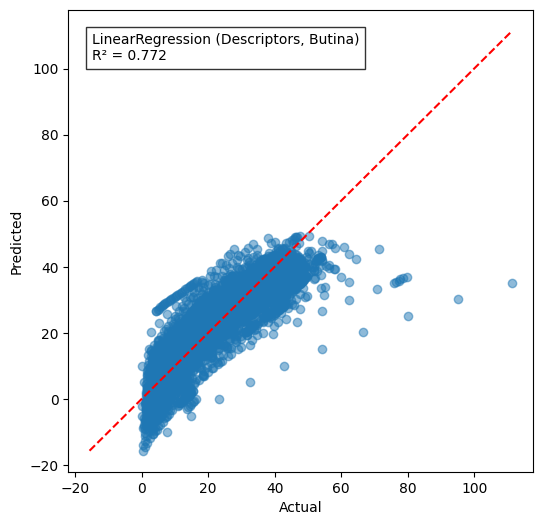

--- LinearRegression | Descriptors | Family split ---


c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 4 is smaller than n_iter=50. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params: {'linearregression__positive': False, 'linearregression__fit_intercept': True}
CV metrics per fold - LinearRegression (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,8.014,4.543,0.668
2,3421.0,5.408,3.980,0.760
3,3426.0,5.108,3.485,0.778
4,3410.0,5.688,4.015,0.728
5,3418.0,5.097,3.547,0.819
mean,NaN,5.863,3.914,0.751
std,NaN,1.227,0.427,0.057


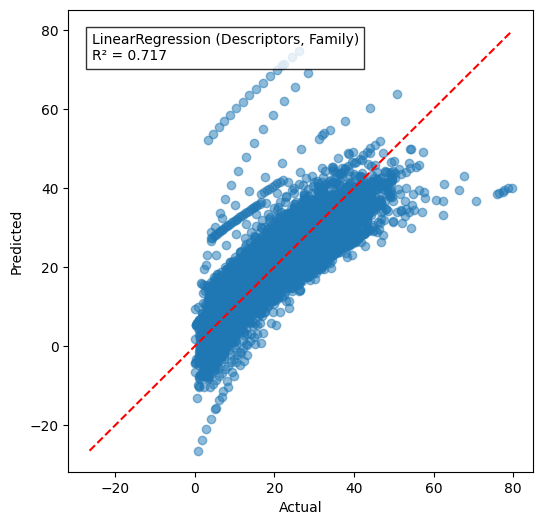

--- LinearRegression | Morgan | Butina split ---


c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 4 is smaller than n_iter=20. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params: {'linearregression__positive': False, 'linearregression__fit_intercept': True}
CV metrics per fold - LinearRegression (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,7.440,5.486,0.504
2,3410.0,7.355,5.395,0.516
3,3419.0,6.641,4.650,0.662
4,3410.0,7.827,5.793,0.659
5,3409.0,7.396,5.311,0.613
mean,NaN,7.332,5.327,0.591
std,NaN,0.429,0.420,0.077


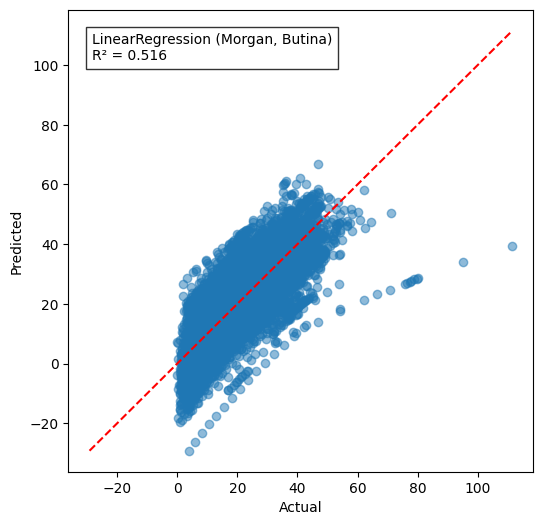

--- LinearRegression | Morgan | Family split ---


c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 4 is smaller than n_iter=20. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
1 fits failed out of a total of 20.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Mo

best params: {'linearregression__positive': False, 'linearregression__fit_intercept': False}
CV metrics per fold - LinearRegression (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,11.541,8.285,0.312
2,3421.0,12.730,8.385,-0.328
3,3426.0,11.769,8.303,-0.179
4,3410.0,10.605,7.699,0.056
5,3418.0,10.975,7.524,0.162
mean,NaN,11.524,8.039,0.004
std,NaN,0.815,0.397,0.258


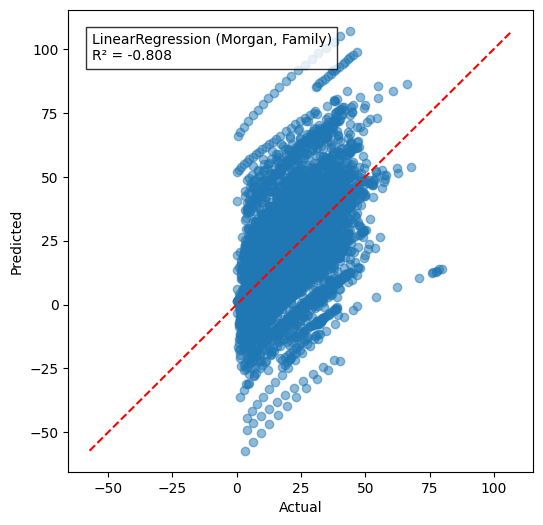

In [3]:
from sklearn.linear_model import LinearRegression

params = {
    'linearregression__fit_intercept': [True, False],
    'linearregression__positive': [True, False],
}
fit_all('LinearRegression', lambda sc: make_pipeline(sc, LinearRegression()), params)

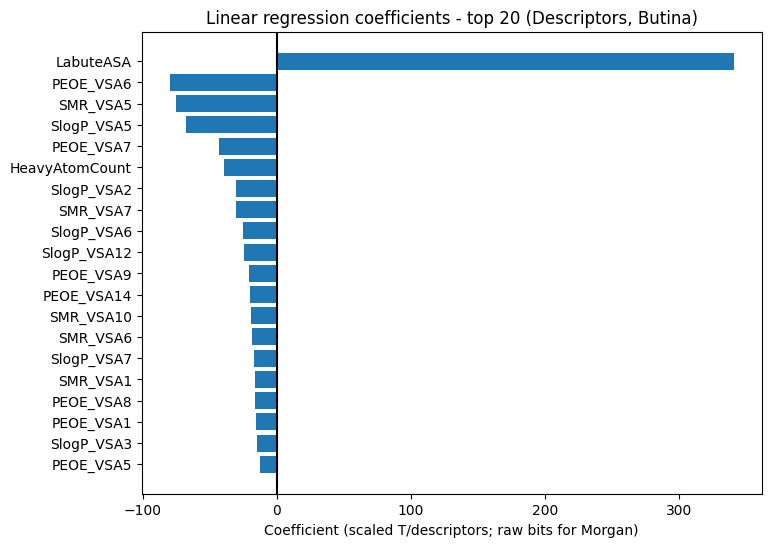

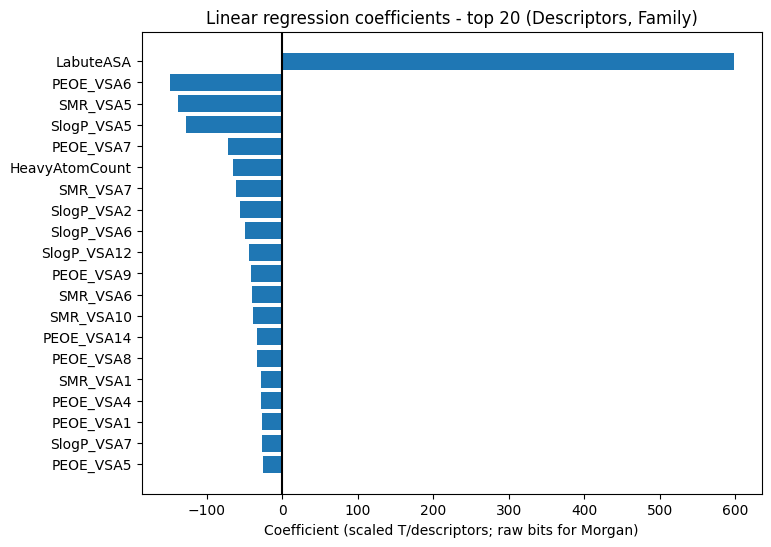

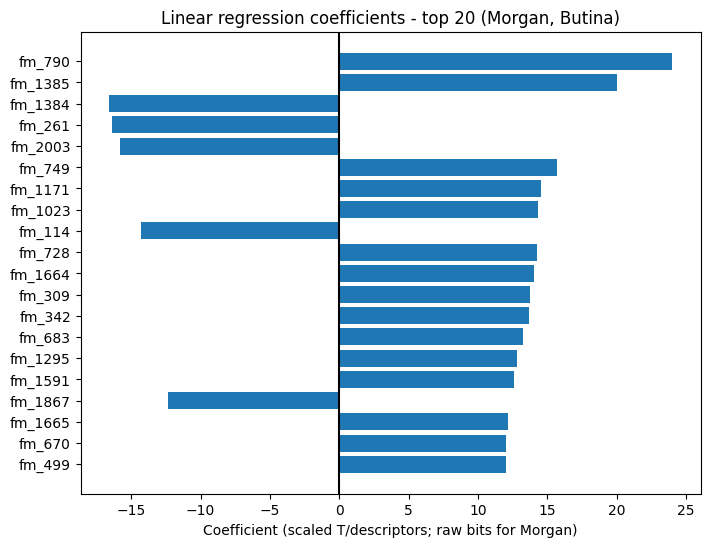

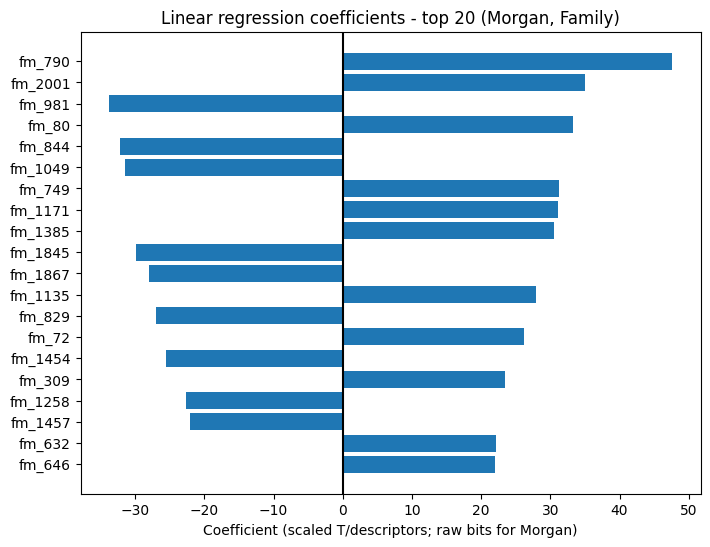

In [4]:
plot_coefs('LinearRegression', 'Linear regression coefficients')

### Ridge Regression

--- Ridge | Descriptors | Butina split ---
best params: {'ridge__alpha': np.float64(4.676478725076045), 'ridge__fit_intercept': True}
CV metrics per fold - Ridge (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,5.128,3.690,0.764
2,3410.0,5.053,3.545,0.771
3,3419.0,5.516,3.987,0.767
4,3410.0,6.972,4.289,0.729
5,3409.0,5.911,4.015,0.753
mean,NaN,5.716,3.905,0.757
std,NaN,0.781,0.293,0.017


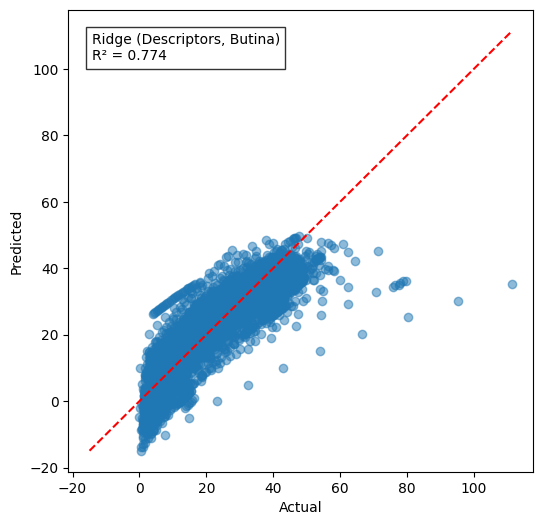

--- Ridge | Descriptors | Family split ---
best params: {'ridge__alpha': np.float64(0.5450293694558254), 'ridge__fit_intercept': True}
CV metrics per fold - Ridge (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,7.161,4.357,0.735
2,3421.0,5.406,3.960,0.761
3,3426.0,5.056,3.482,0.782
4,3410.0,5.663,4.006,0.731
5,3418.0,5.103,3.566,0.819
mean,NaN,5.678,3.874,0.765
std,NaN,0.865,0.356,0.036


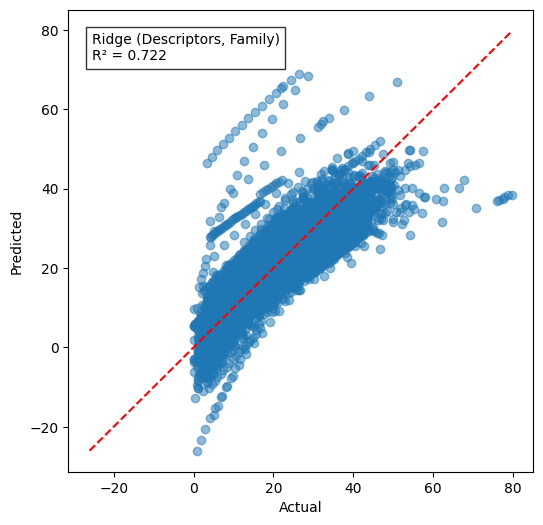

--- Ridge | Morgan | Butina split ---
best params: {'ridge__alpha': np.float64(4.676478725076045), 'ridge__fit_intercept': True}
CV metrics per fold - Ridge (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.811,3.514,0.793
2,3410.0,5.126,3.671,0.765
3,3419.0,5.396,3.773,0.777
4,3410.0,5.338,4.009,0.841
5,3409.0,6.139,4.173,0.733
mean,NaN,5.362,3.828,0.782
std,NaN,0.491,0.264,0.040


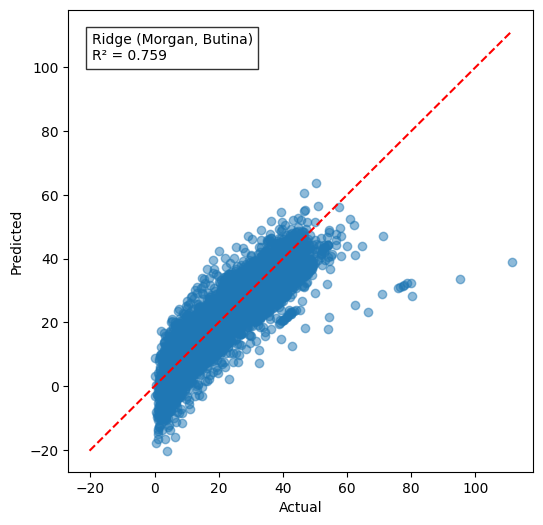

--- Ridge | Morgan | Family split ---
best params: {'ridge__alpha': np.float64(4.676478725076045), 'ridge__fit_intercept': True}
CV metrics per fold - Ridge (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,5.873,4.187,0.822
2,3421.0,5.757,4.049,0.728
3,3426.0,5.438,3.881,0.748
4,3410.0,5.403,3.935,0.755
5,3418.0,5.874,4.160,0.760
mean,NaN,5.669,4.042,0.763
std,NaN,0.232,0.135,0.035


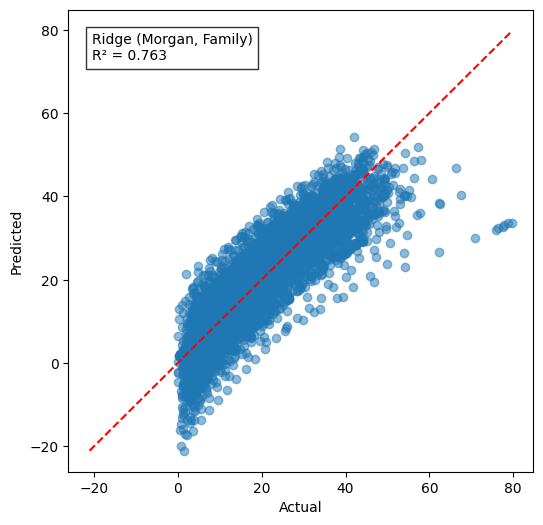

In [5]:
from sklearn.linear_model import Ridge

params = {
    'ridge__alpha': loguniform(1e-3, 1e3),
    'ridge__fit_intercept': [True, False],
}
fit_all('Ridge', lambda sc: make_pipeline(sc, Ridge()), params)

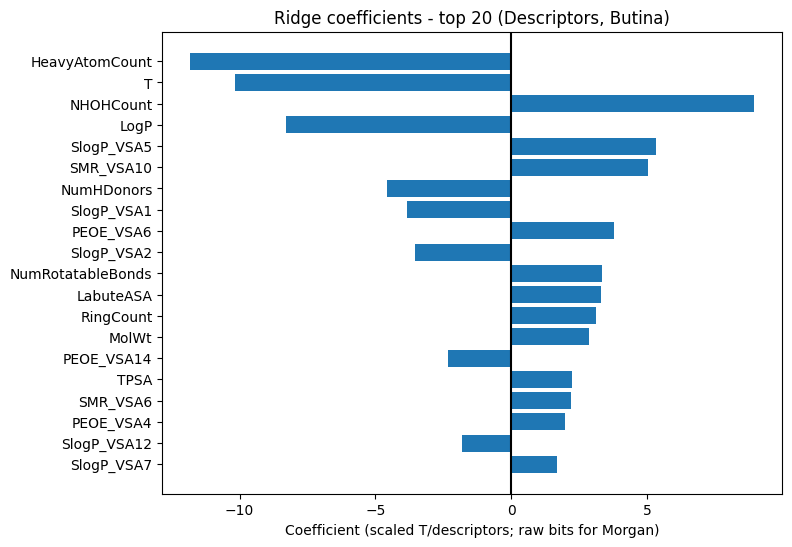

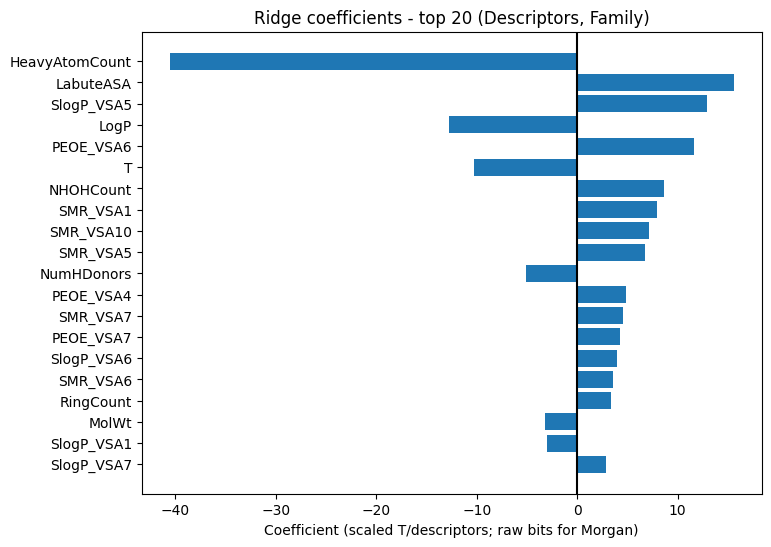

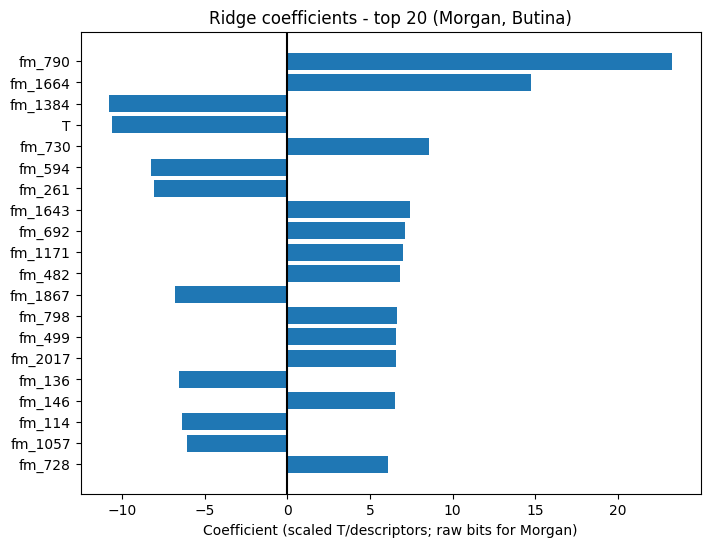

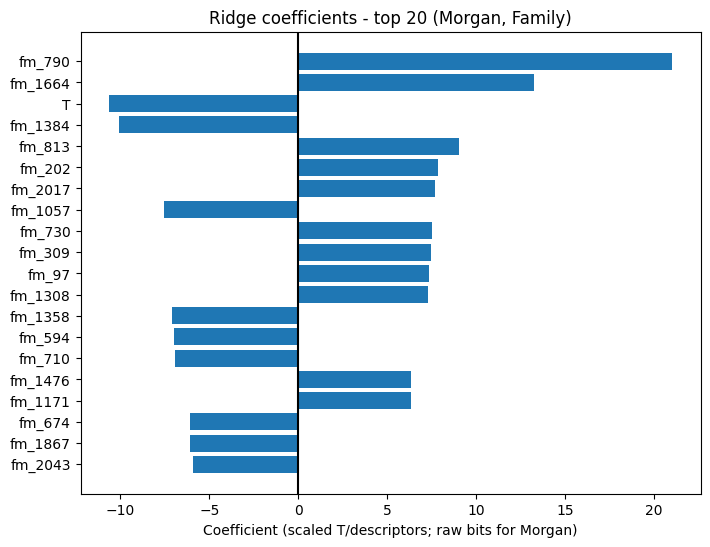

In [6]:
plot_coefs('Ridge', 'Ridge coefficients')

### SVR

--- SVR | Descriptors | Butina split ---
best params: {'regressor__svr__C': np.float64(0.5415244119402537), 'regressor__svr__epsilon': np.float64(0.005670807781371429), 'regressor__svr__gamma': np.float64(0.012561043700013555)}
CV metrics per fold - SVR (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.269,2.110,0.904
2,3410.0,3.577,2.182,0.885
3,3419.0,4.449,2.553,0.848
4,3410.0,7.947,3.210,0.648
5,3409.0,6.364,2.925,0.713
mean,NaN,5.121,2.596,0.800
std,NaN,1.987,0.473,0.113


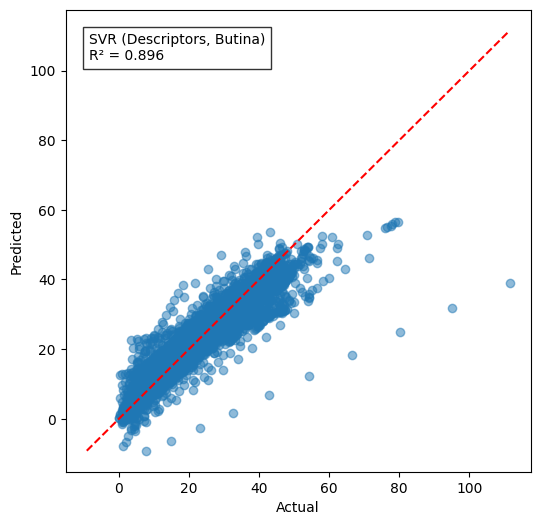

--- SVR | Descriptors | Family split ---
best params: {'regressor__svr__C': np.float64(213.6832907235874), 'regressor__svr__epsilon': np.float64(0.0033572967053517922), 'regressor__svr__gamma': np.float64(0.000533703276260396)}
CV metrics per fold - SVR (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,7.918,3.443,0.676
2,3421.0,4.104,2.388,0.862
3,3426.0,3.554,1.855,0.892
4,3410.0,4.071,2.253,0.861
5,3418.0,4.665,2.423,0.849
mean,NaN,4.862,2.473,0.828
std,NaN,1.753,0.588,0.086


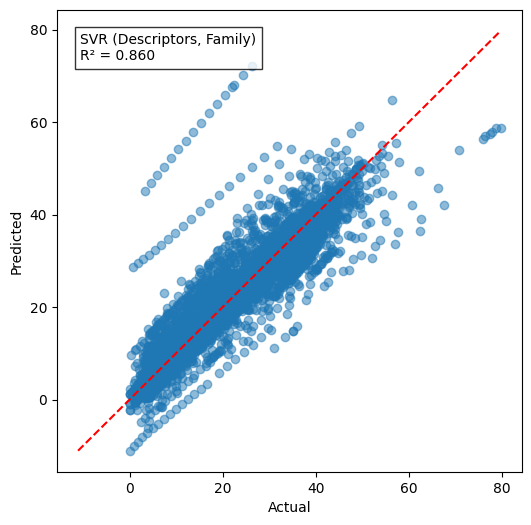

--- SVR | Morgan | Butina split ---
best params: {'regressor__svr__C': np.float64(5.342937261279771), 'regressor__svr__epsilon': np.float64(0.005265139631677754), 'regressor__svr__gamma': np.float64(0.0280163515871626)}
CV metrics per fold - SVR (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.865,2.831,0.866
2,3410.0,4.048,2.809,0.853
3,3419.0,4.701,3.076,0.831
4,3410.0,3.800,2.659,0.920
5,3409.0,5.320,3.154,0.800
mean,NaN,4.347,2.906,0.854
std,NaN,0.651,0.204,0.045


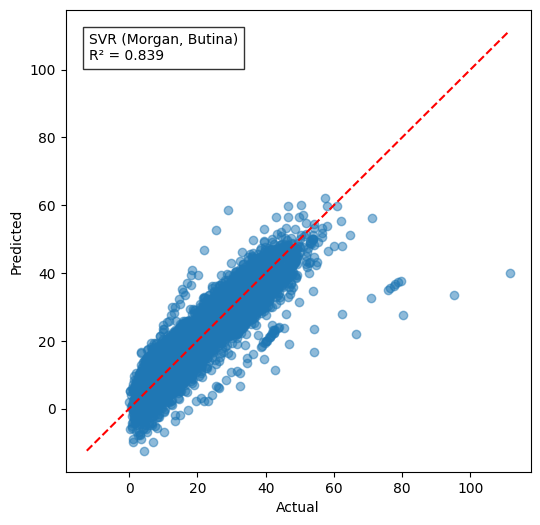

--- SVR | Morgan | Family split ---
best params: {'regressor__svr__C': np.float64(5.342937261279771), 'regressor__svr__epsilon': np.float64(0.005265139631677754), 'regressor__svr__gamma': np.float64(0.0280163515871626)}
CV metrics per fold - SVR (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.668,3.081,0.887
2,3421.0,4.488,3.113,0.835
3,3426.0,4.501,3.021,0.827
4,3410.0,4.239,2.864,0.849
5,3418.0,4.977,3.259,0.828
mean,NaN,4.575,3.068,0.845
std,NaN,0.272,0.143,0.025


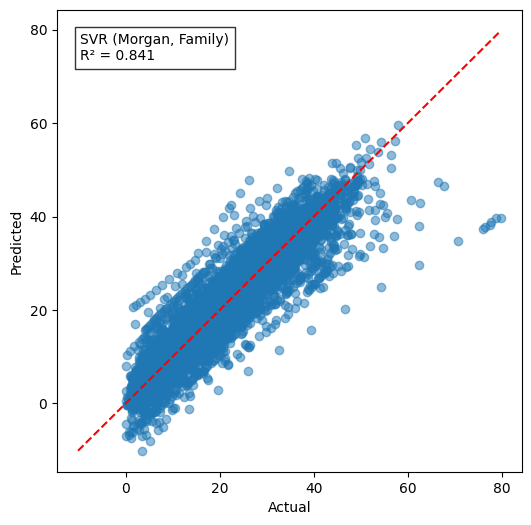

In [7]:
from sklearn.svm import SVR

params = {
    'regressor__svr__C': loguniform(1e-1, 1e3),
    'regressor__svr__epsilon': loguniform(1e-3, 3e-1),    # in standardized-y units
    'regressor__svr__gamma': loguniform(1e-4, 1e0),
}
fit_all('SVR', lambda sc: scaled(SVR(kernel='rbf'), sc), params, n_iter=20)

### Decision Tree

--- DecisionTree | Descriptors | Butina split ---
best params: {'max_depth': 20, 'min_samples_leaf': 10, 'min_samples_split': 5}
CV metrics per fold - DecisionTree (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,6.056,3.484,0.671
2,3410.0,4.463,3.127,0.822
3,3419.0,5.444,3.306,0.773
4,3410.0,5.365,3.445,0.840
5,3409.0,5.534,3.393,0.783
mean,NaN,5.373,3.351,0.778
std,NaN,0.576,0.142,0.065


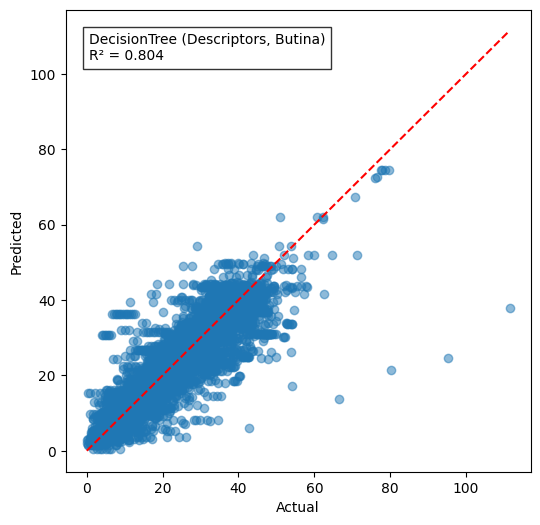

--- DecisionTree | Descriptors | Family split ---
best params: {'max_depth': 20, 'min_samples_leaf': 23, 'min_samples_split': 29}
CV metrics per fold - DecisionTree (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,5.158,3.488,0.863
2,3421.0,4.965,3.309,0.798
3,3426.0,4.993,3.158,0.788
4,3410.0,6.190,3.566,0.678
5,3418.0,5.180,3.362,0.813
mean,NaN,5.297,3.377,0.788
std,NaN,0.508,0.159,0.068


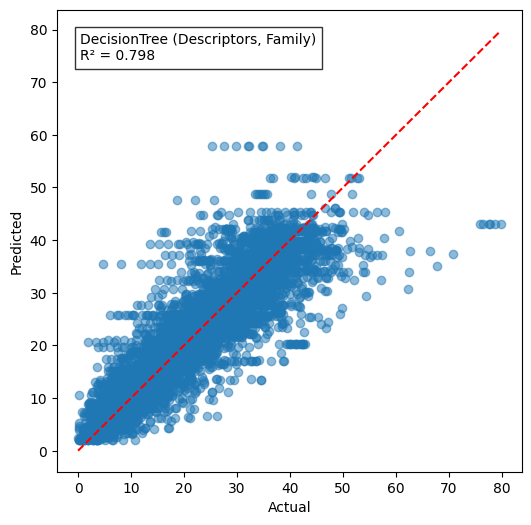

--- DecisionTree | Morgan | Butina split ---
best params: {'max_depth': 20, 'min_samples_leaf': 6, 'min_samples_split': 3}
CV metrics per fold - DecisionTree (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.785,3.470,0.795
2,3410.0,5.019,3.531,0.774
3,3419.0,5.553,3.650,0.764
4,3410.0,4.919,3.354,0.865
5,3409.0,7.470,4.326,0.605
mean,NaN,5.549,3.666,0.761
std,NaN,1.113,0.384,0.096


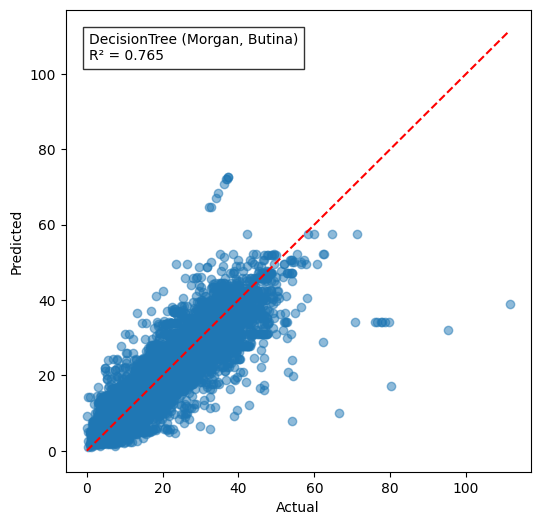

--- DecisionTree | Morgan | Family split ---
best params: {'max_depth': 20, 'min_samples_leaf': 6, 'min_samples_split': 3}
CV metrics per fold - DecisionTree (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,5.917,3.900,0.819
2,3421.0,5.203,3.650,0.778
3,3426.0,5.473,3.597,0.745
4,3410.0,5.343,3.792,0.760
5,3418.0,6.029,3.807,0.747
mean,NaN,5.593,3.749,0.770
std,NaN,0.362,0.124,0.031


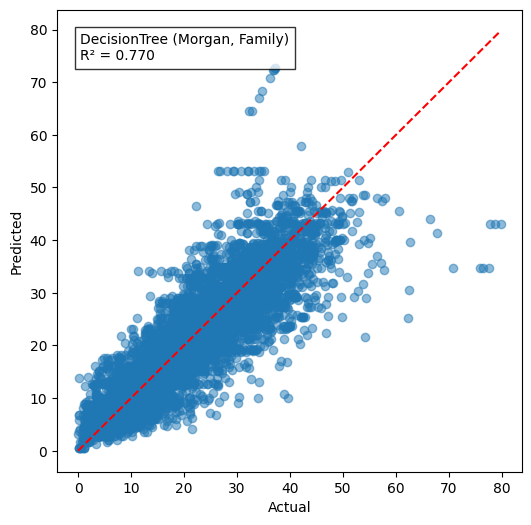

In [8]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

params = {
    'max_depth': [3, 6, 9, 12, 15, 20],
    'min_samples_leaf': randint(1, 30),
    'min_samples_split': randint(2, 30),
}
fit_all('DecisionTree', lambda sc: DecisionTreeRegressor(random_state=42), params)

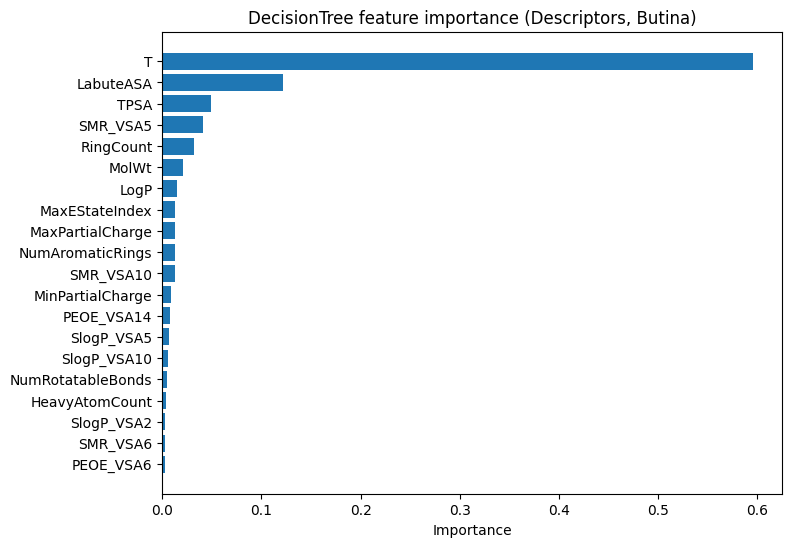

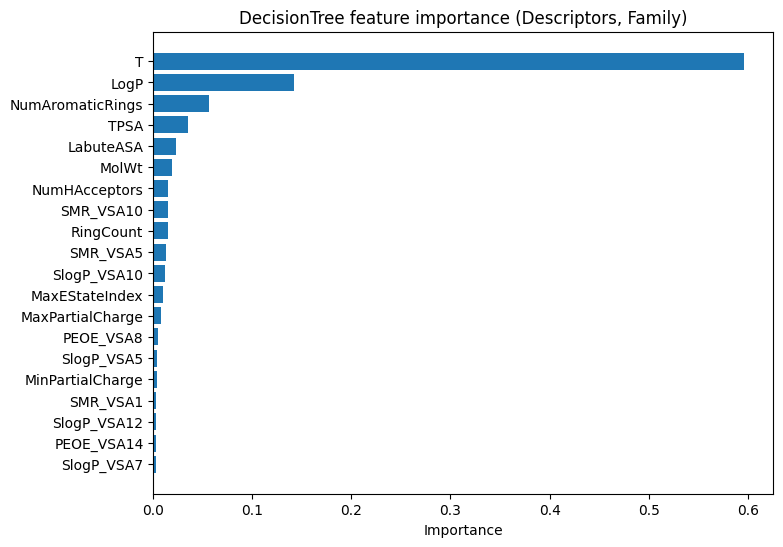

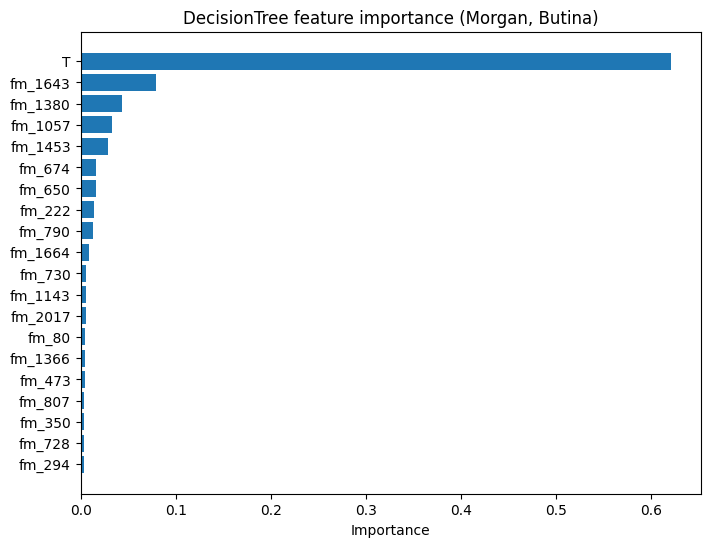

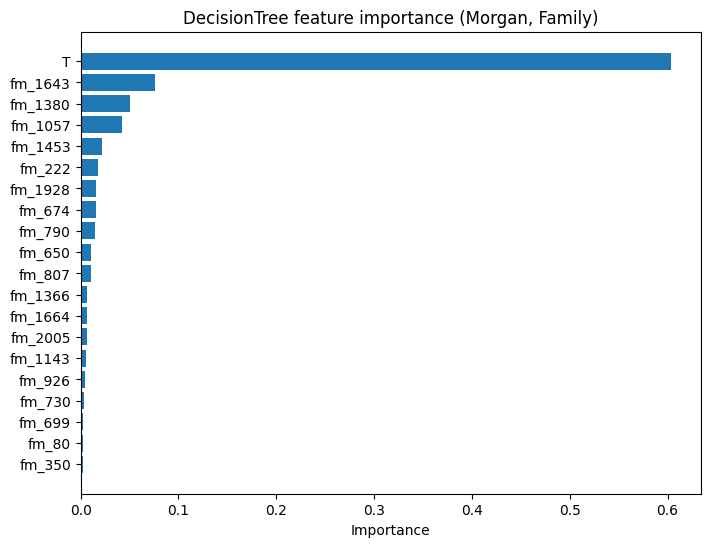

In [9]:
plot_importance('DecisionTree')

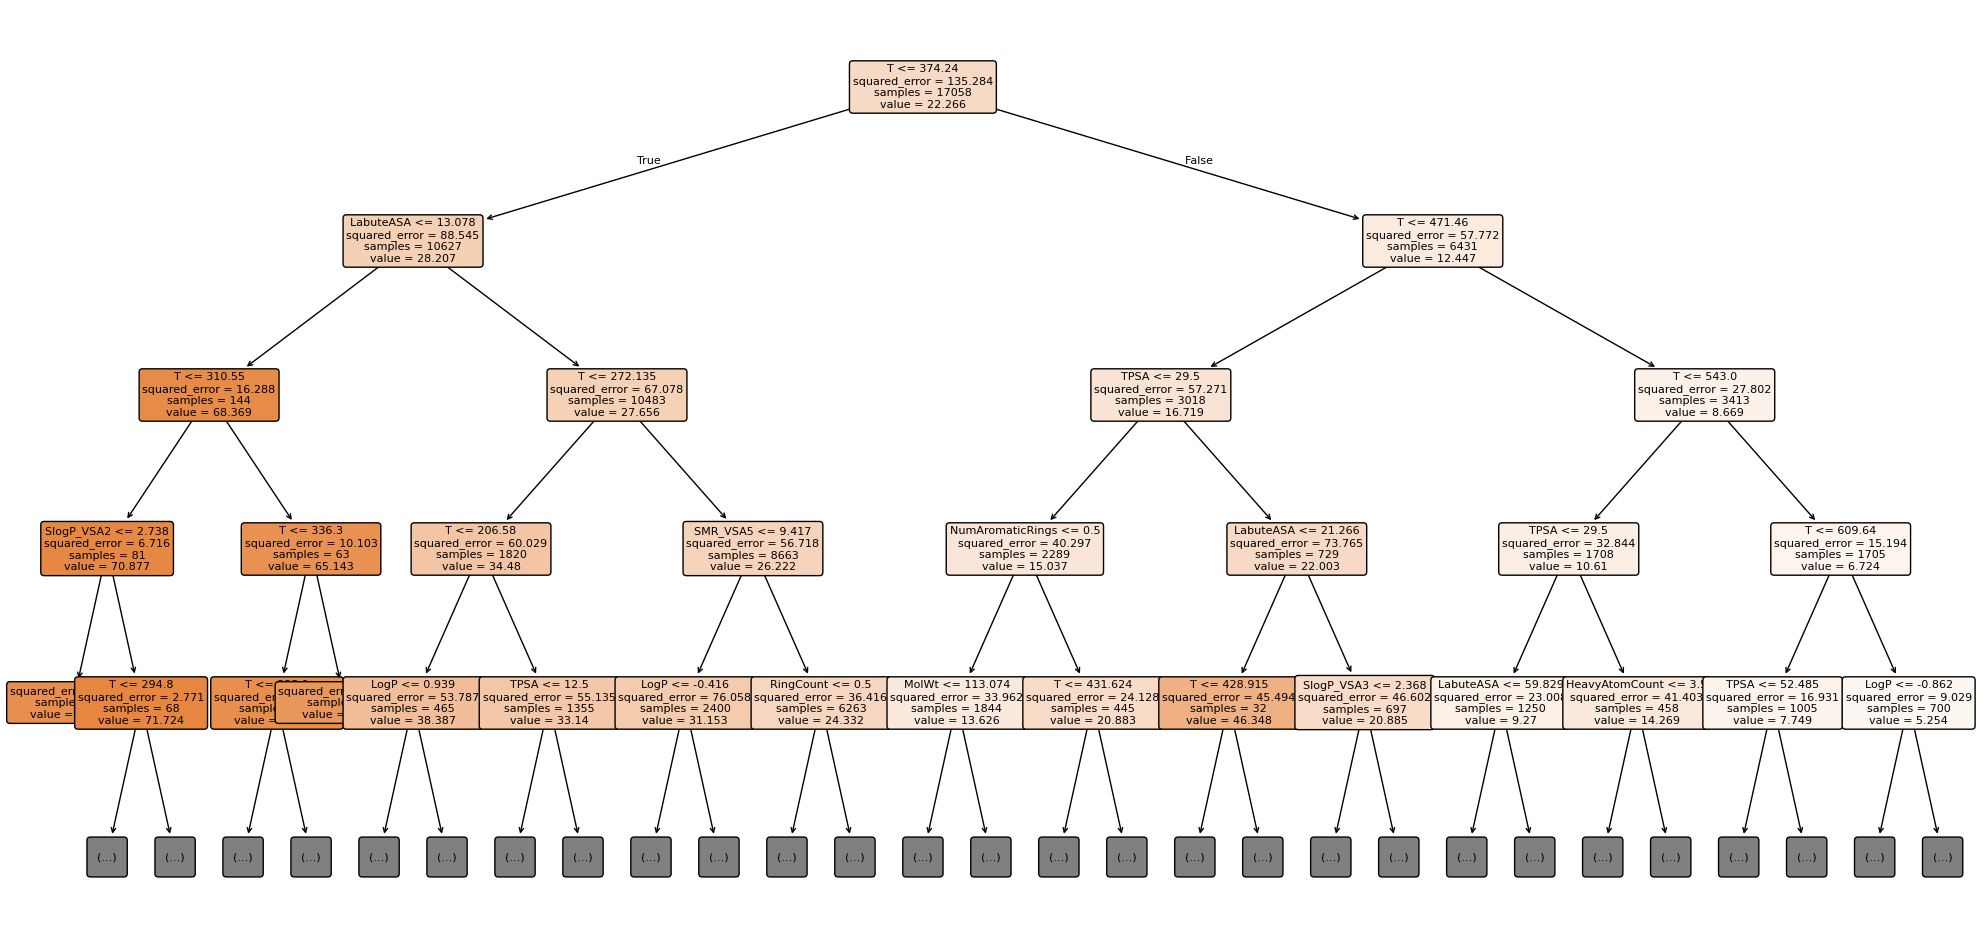

In [10]:
# tree structure (Descriptors, Butina split)
plt.figure(figsize=(25, 12))
plot_tree(models[('DecisionTree', 'Descriptors', 'Butina')], feature_names=FEATURES['Descriptors'],
          max_depth=4, filled=True, rounded=True, fontsize=8)
plt.show()

### Random Forest

--- RandomForest | Descriptors | Butina split ---
best params: {'max_depth': None, 'max_features': np.float64(0.40921304830970556), 'min_samples_leaf': 3, 'n_estimators': 314}
CV metrics per fold - RandomForest (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.967,2.386,0.859
2,3410.0,3.183,2.174,0.909
3,3419.0,4.167,2.401,0.867
4,3410.0,3.878,2.526,0.916
5,3409.0,4.608,2.659,0.850
mean,NaN,3.961,2.429,0.880
std,NaN,0.518,0.180,0.030


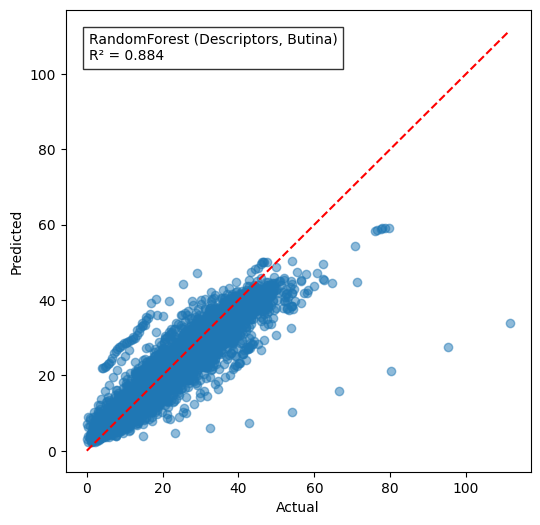

--- RandomForest | Descriptors | Family split ---
best params: {'max_depth': None, 'max_features': np.float64(0.61534947637868), 'min_samples_leaf': 2, 'n_estimators': 487}
CV metrics per fold - RandomForest (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,3.878,2.339,0.922
2,3421.0,3.763,2.408,0.884
3,3426.0,3.917,2.206,0.869
4,3410.0,4.565,2.506,0.825
5,3418.0,3.651,2.242,0.907
mean,NaN,3.955,2.340,0.882
std,NaN,0.356,0.122,0.038


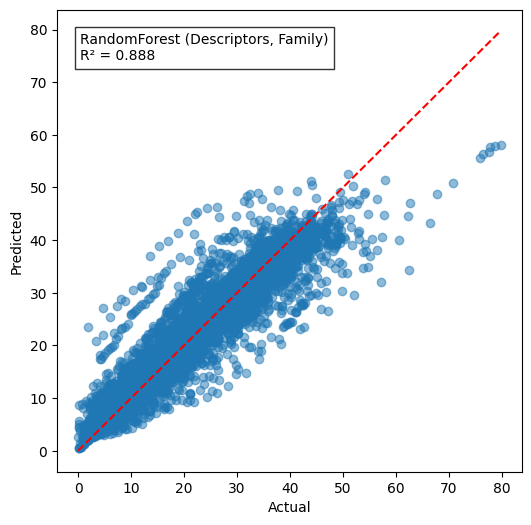

--- RandomForest | Morgan | Butina split ---
best params: {'max_depth': 15, 'max_features': np.float64(0.20771054180315005), 'min_samples_leaf': 2, 'n_estimators': 291}
CV metrics per fold - RandomForest (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.500,3.409,0.819
2,3410.0,4.491,3.475,0.819
3,3419.0,5.363,3.698,0.780
4,3410.0,4.789,3.539,0.872
5,3409.0,6.374,3.981,0.713
mean,NaN,5.103,3.620,0.801
std,NaN,0.793,0.228,0.059


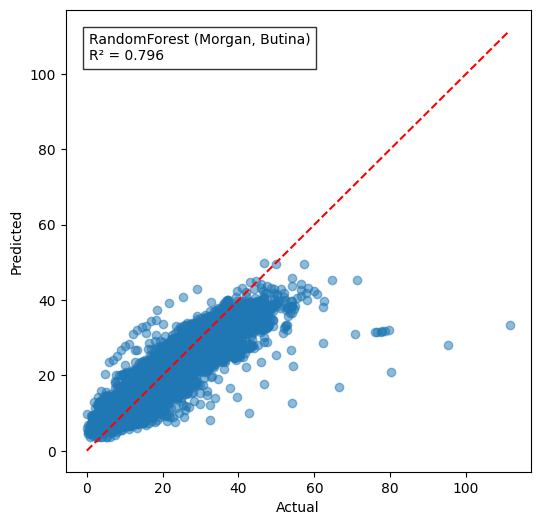

--- RandomForest | Morgan | Family split ---
best params: {'max_depth': None, 'max_features': np.float64(0.051203728088487305), 'min_samples_leaf': 3, 'n_estimators': 314}
CV metrics per fold - RandomForest (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,5.593,3.852,0.838
2,3421.0,4.936,3.637,0.800
3,3426.0,5.037,3.554,0.784
4,3410.0,4.937,3.665,0.795
5,3418.0,5.797,3.714,0.766
mean,NaN,5.260,3.684,0.797
std,NaN,0.405,0.110,0.027


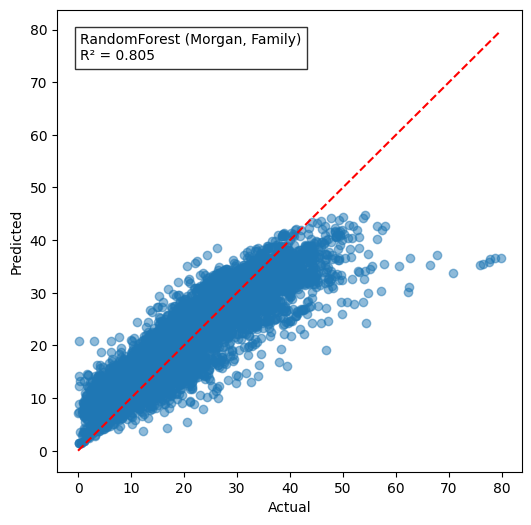

In [11]:
from sklearn.ensemble import RandomForestRegressor

def rf_params(fs):
    return {
        'n_estimators': randint(100, 500),
        'max_depth': [6, 9, 12, 15, None],
        'min_samples_leaf': randint(1, 10),
        # fewer candidate features per split for the 2049-bit fingerprint
        'max_features': uniform(0.3, 0.7) if fs == 'Descriptors' else uniform(0.02, 0.2),
    }

fit_all('RandomForest', lambda sc: RandomForestRegressor(random_state=42, n_jobs=1), rf_params, n_iter=20)

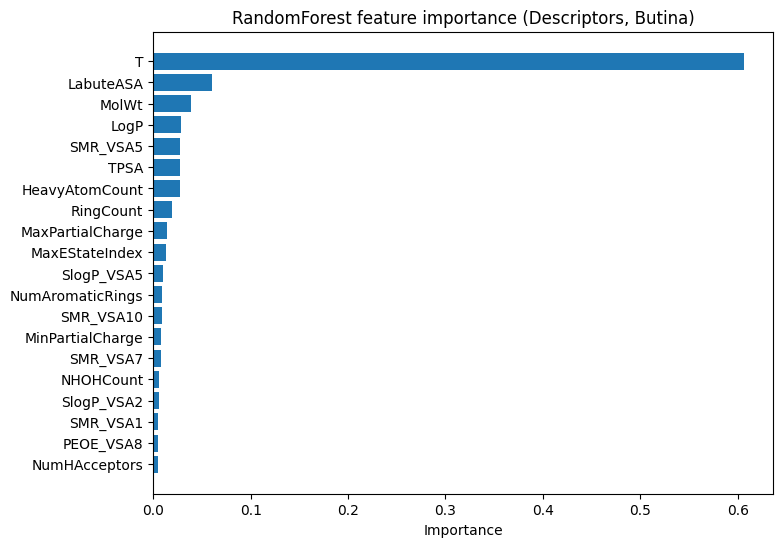

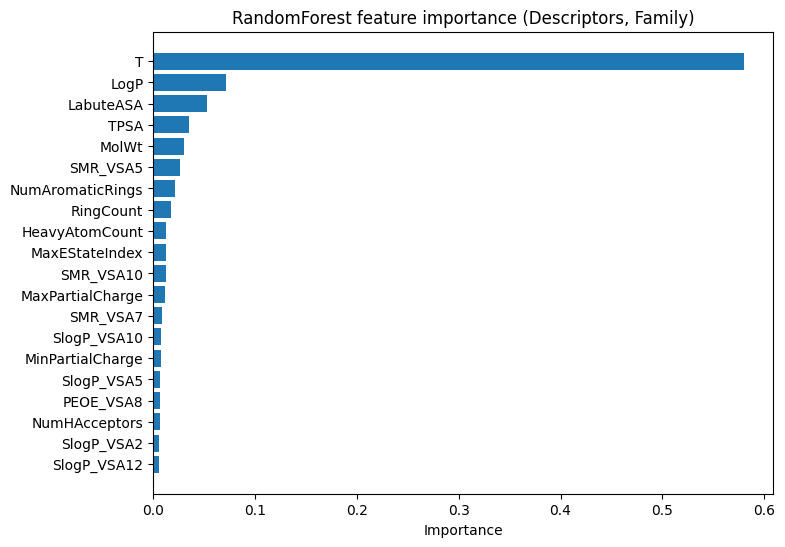

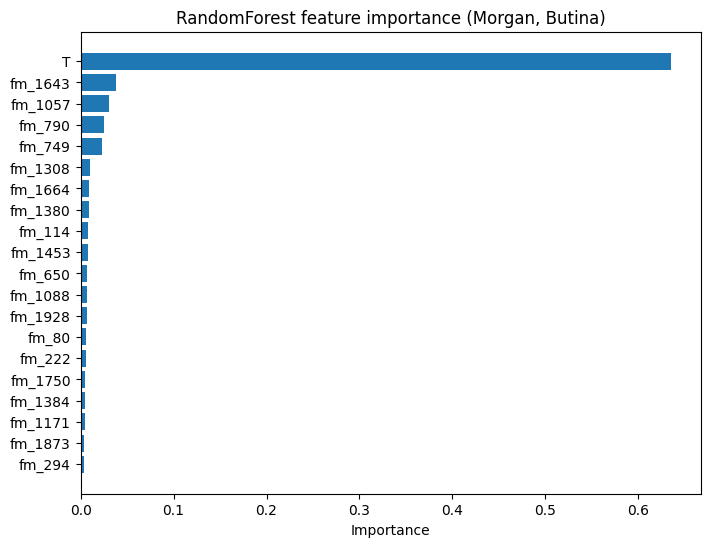

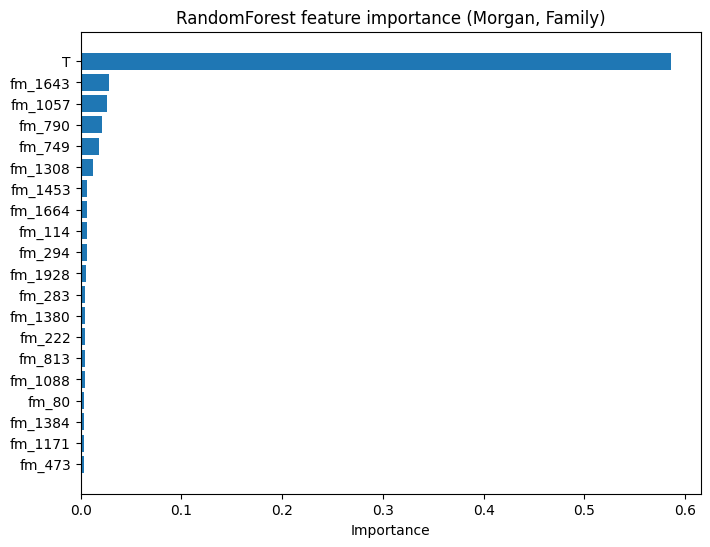

In [12]:
plot_importance('RandomForest')

### Gaussian Process Regressor

Exact GPR scales as O(n³) in memory and time, so it cannot be tuned with CV on ~17k points. It is trained on a random subsample of the training set; the kernel hyperparameters are optimized by marginal likelihood. Morgan bits are left unscaled (only `T` is standardized), so a single RBF length-scale is applied over 0/1 bits and standardized `T`.

Descriptors Butina 2.09**2 * RBF(length_scale=4.54) + WhiteKernel(noise_level=0.00296)


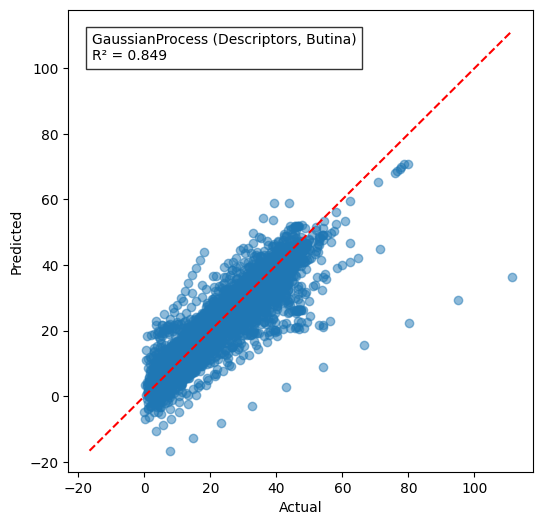

Descriptors Family 2.02**2 * RBF(length_scale=4.7) + WhiteKernel(noise_level=0.00256)


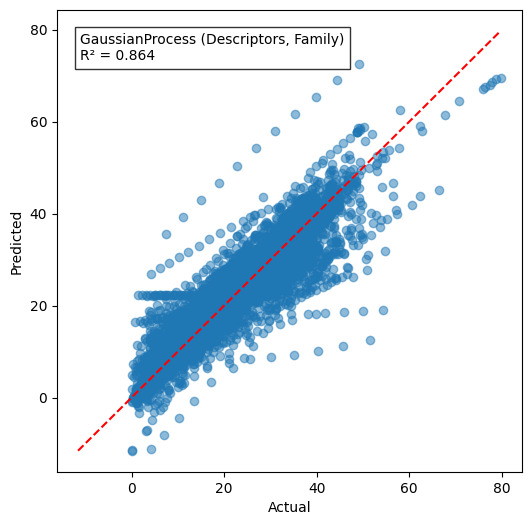

Morgan Butina 1.3**2 * RBF(length_scale=4.55) + WhiteKernel(noise_level=0.00648)


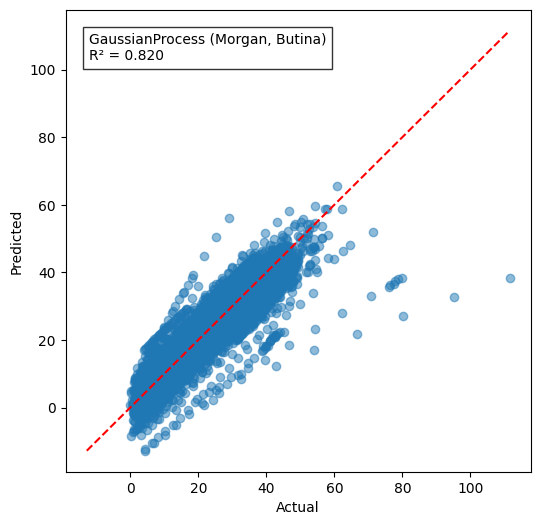

Morgan Family 1.04**2 * RBF(length_scale=3.58) + WhiteKernel(noise_level=0.00467)


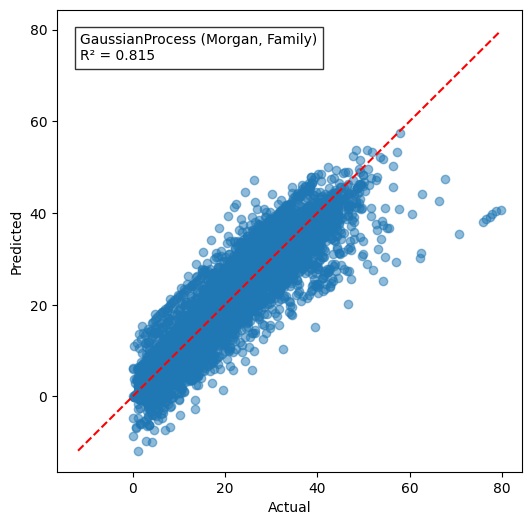

In [13]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

N_GPR = 2000
kernel = ConstantKernel(1.0) * RBF(length_scale=5.0) + WhiteKernel(noise_level=0.1)

for fs in FSETS:
    reg = make_pipeline(make_scaler(fs),
                        GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                                 n_restarts_optimizer=2, random_state=42))
    for s in SPLITS:
        d = data[(fs, s)]
        pos = np.random.default_rng(42).choice(len(d['X_train']), size=min(N_GPR, len(d['X_train'])), replace=False)
        gpr = clone(reg).fit(d['X_train'].iloc[pos], d['y_train'].iloc[pos])
        print(fs, s, gpr[-1].kernel_)
        record(gpr, 'GaussianProcess', fs, s)
        plot_actual_vs_predicted(gpr, d['X_test'], d['y_test'], f'GaussianProcess ({fs}, {s})')

### Gradient Boosting Regressor

--- GradientBoosting | Descriptors | Butina split ---
best params: {'learning_rate': np.float64(0.1601531217136121), 'loss': 'squared_error', 'max_depth': 4, 'n_estimators': 388, 'subsample': np.float64(0.8423839899124046)}
CV metrics per fold - GradientBoosting (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.338,1.954,0.900
2,3410.0,3.209,2.031,0.908
3,3419.0,3.871,2.251,0.885
4,3410.0,3.508,2.149,0.931
5,3409.0,4.468,2.558,0.859
mean,NaN,3.679,2.189,0.897
std,NaN,0.506,0.235,0.027


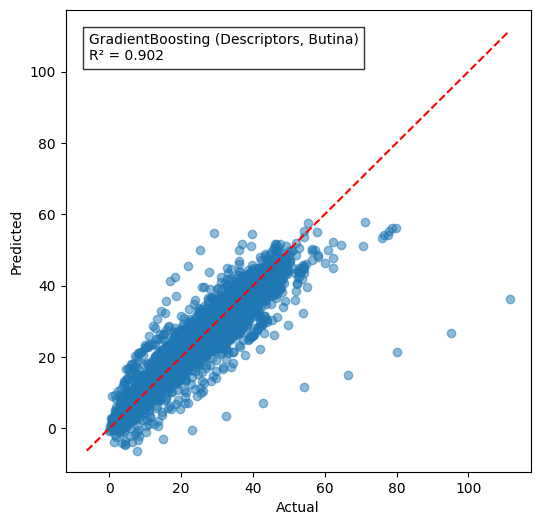

--- GradientBoosting | Descriptors | Family split ---
best params: {'learning_rate': np.float64(0.07357031542417702), 'loss': 'squared_error', 'max_depth': 5, 'n_estimators': 287, 'subsample': np.float64(0.8170784332632994)}
CV metrics per fold - GradientBoosting (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.210,2.460,0.908
2,3421.0,3.368,2.137,0.907
3,3426.0,3.699,1.995,0.883
4,3410.0,4.043,2.223,0.863
5,3418.0,3.514,2.109,0.914
mean,NaN,3.767,2.185,0.895
std,NaN,0.354,0.174,0.022


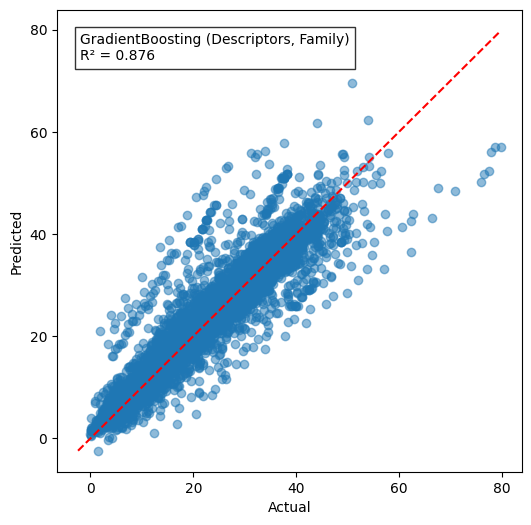

--- GradientBoosting | Morgan | Butina split ---
best params: {'learning_rate': np.float64(0.08167611317882542), 'loss': 'huber', 'max_depth': 7, 'n_estimators': 352, 'subsample': np.float64(0.7727780074568463)}
CV metrics per fold - GradientBoosting (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.685,2.673,0.878
2,3410.0,4.510,2.942,0.818
3,3419.0,4.818,3.021,0.822
4,3410.0,3.777,2.747,0.921
5,3409.0,5.491,3.332,0.787
mean,NaN,4.456,2.943,0.845
std,NaN,0.752,0.259,0.054


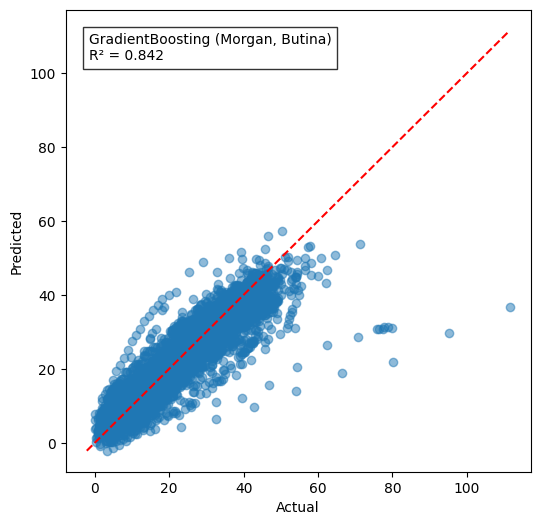

--- GradientBoosting | Morgan | Family split ---
best params: {'learning_rate': np.float64(0.08167611317882542), 'loss': 'huber', 'max_depth': 7, 'n_estimators': 352, 'subsample': np.float64(0.7727780074568463)}
CV metrics per fold - GradientBoosting (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,5.309,3.476,0.854
2,3421.0,4.607,3.105,0.826
3,3426.0,4.435,2.799,0.833
4,3410.0,4.263,2.990,0.847
5,3418.0,5.337,3.249,0.802
mean,NaN,4.790,3.124,0.832
std,NaN,0.501,0.257,0.021


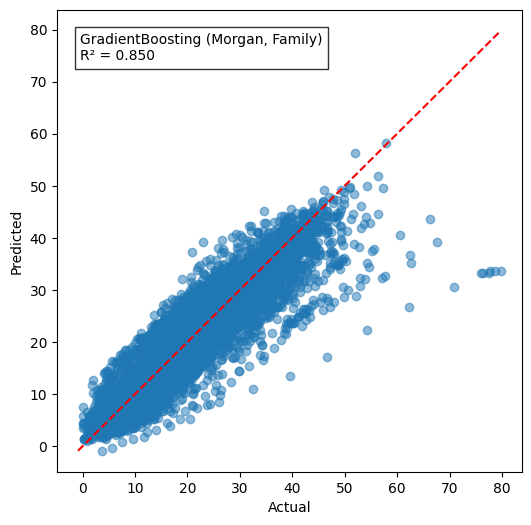

In [14]:
from sklearn.ensemble import GradientBoostingRegressor

params = {
    'n_estimators': randint(100, 500),
    'learning_rate': loguniform(1e-2, 3e-1),
    'max_depth': randint(2, 8),
    'subsample': uniform(0.6, 0.4),
    'loss': ['squared_error', 'huber'],
}
fit_all('GradientBoosting', lambda sc: GradientBoostingRegressor(random_state=42), params, n_iter=20)

### XGBoost

--- XGBoost | Descriptors | Butina split ---
best params: {'colsample_bytree': np.float64(0.8211279907631631), 'learning_rate': np.float64(0.09598794165786155), 'max_depth': 3, 'min_child_weight': 3, 'n_estimators': 917, 'reg_alpha': np.float64(1.7341446371602074), 'reg_lambda': np.float64(3.239721657669414), 'subsample': np.float64(0.8045369595443751)}
CV metrics per fold - XGBoost (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.550,2.004,0.887
2,3410.0,3.153,2.030,0.911
3,3419.0,3.915,2.226,0.883
4,3410.0,3.607,2.271,0.928
5,3409.0,4.344,2.519,0.866
mean,NaN,3.714,2.210,0.895
std,NaN,0.444,0.209,0.024


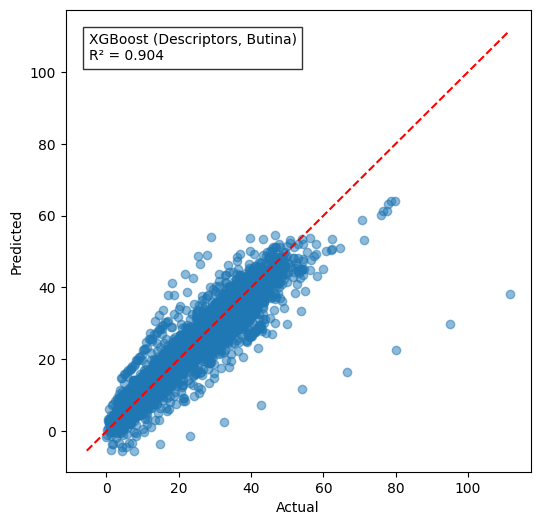

--- XGBoost | Descriptors | Family split ---
best params: {'colsample_bytree': np.float64(0.8684574067296202), 'learning_rate': np.float64(0.11400756657588752), 'max_depth': 8, 'min_child_weight': 2, 'n_estimators': 884, 'reg_alpha': np.float64(1.6973395898493489), 'reg_lambda': np.float64(0.9098639943260864), 'subsample': np.float64(0.8835643987640474)}
CV metrics per fold - XGBoost (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,3.889,2.190,0.922
2,3421.0,3.327,2.057,0.909
3,3426.0,3.653,1.925,0.886
4,3410.0,4.060,2.170,0.862
5,3418.0,3.463,2.083,0.917
mean,NaN,3.679,2.085,0.899
std,NaN,0.300,0.105,0.025


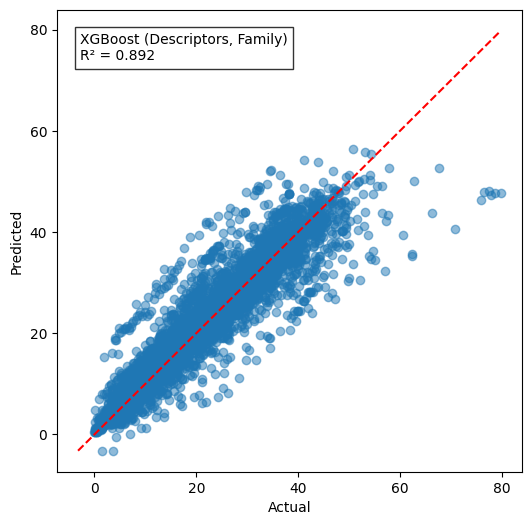

--- XGBoost | Morgan | Butina split ---
best params: {'colsample_bytree': np.float64(0.9533121035675474), 'learning_rate': np.float64(0.10406005609152943), 'max_depth': 8, 'min_child_weight': 9, 'n_estimators': 330, 'reg_alpha': np.float64(1.813656883091508), 'reg_lambda': np.float64(1.316396748153906), 'subsample': np.float64(0.8590760482165449)}
CV metrics per fold - XGBoost (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.688,2.637,0.878
2,3410.0,4.413,2.945,0.826
3,3419.0,4.674,3.005,0.833
4,3410.0,3.685,2.697,0.924
5,3409.0,5.006,3.263,0.823
mean,NaN,4.293,2.909,0.857
std,NaN,0.593,0.252,0.044


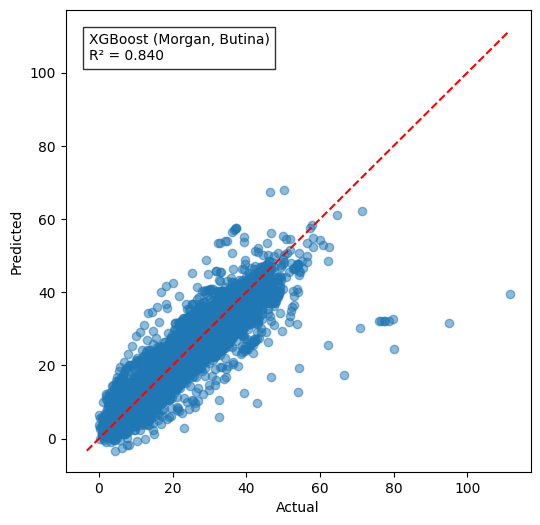

--- XGBoost | Morgan | Family split ---
best params: {'colsample_bytree': np.float64(0.6431565707973218), 'learning_rate': np.float64(0.019114463849152934), 'max_depth': 8, 'min_child_weight': 1, 'n_estimators': 663, 'reg_alpha': np.float64(1.1265511439527673), 'reg_lambda': np.float64(2.5865482592783824), 'subsample': np.float64(0.6557325817623503)}
CV metrics per fold - XGBoost (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.970,3.185,0.872
2,3421.0,4.590,3.058,0.827
3,3426.0,4.422,2.859,0.834
4,3410.0,4.225,2.975,0.850
5,3418.0,5.268,3.168,0.807
mean,NaN,4.695,3.049,0.838
std,NaN,0.421,0.136,0.025


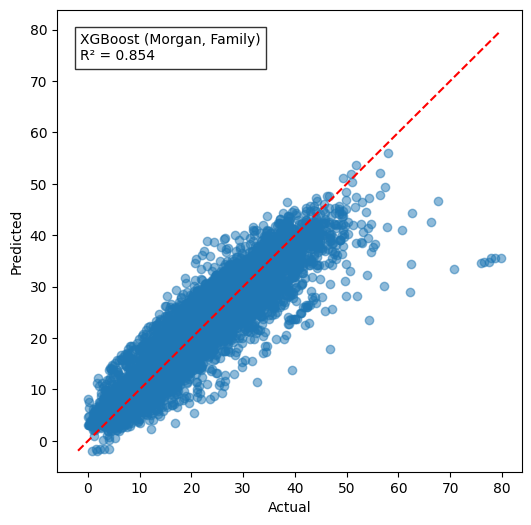

In [15]:
from xgboost import XGBRegressor

params = {
    'n_estimators': randint(100, 1000),
    'max_depth': randint(2, 10),
    'learning_rate': uniform(0.01, 0.29),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_weight': randint(1, 10),
    'reg_alpha': uniform(0, 2),
    'reg_lambda': uniform(0.5, 3),
}
fit_all('XGBoost', lambda sc: XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=1), params)

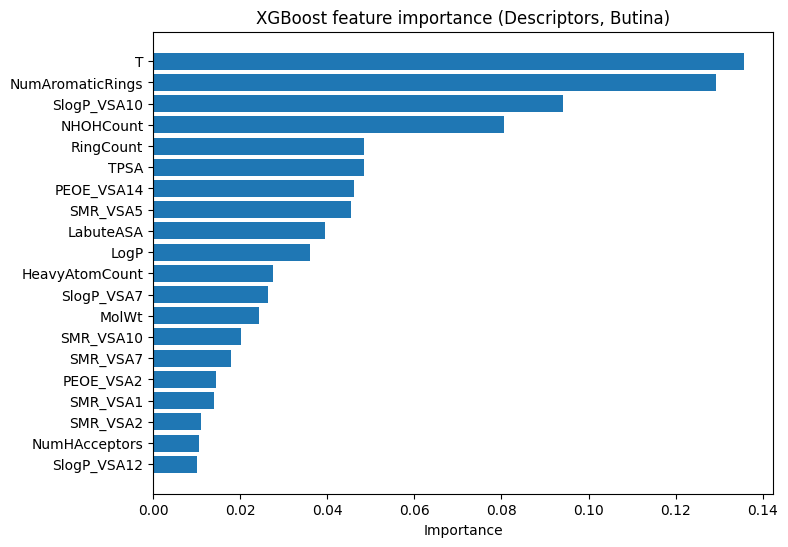

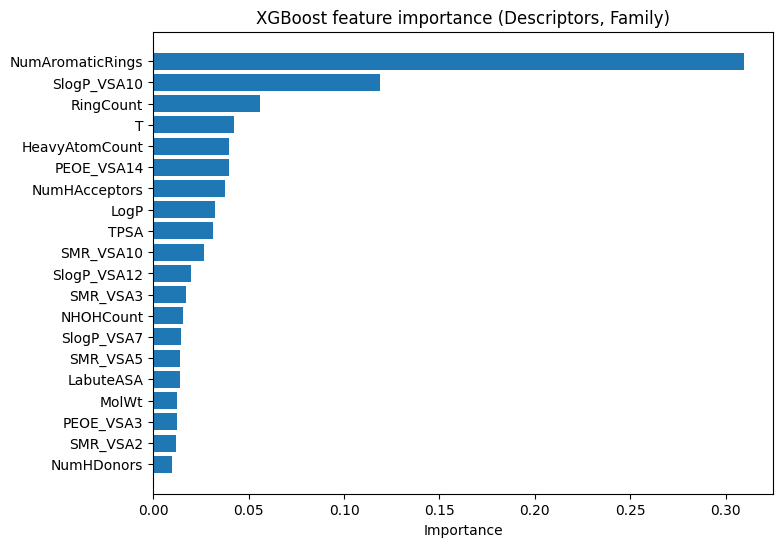

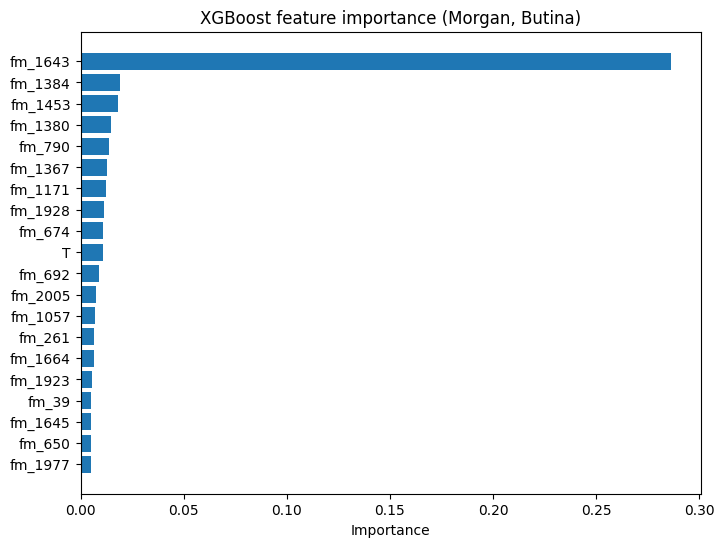

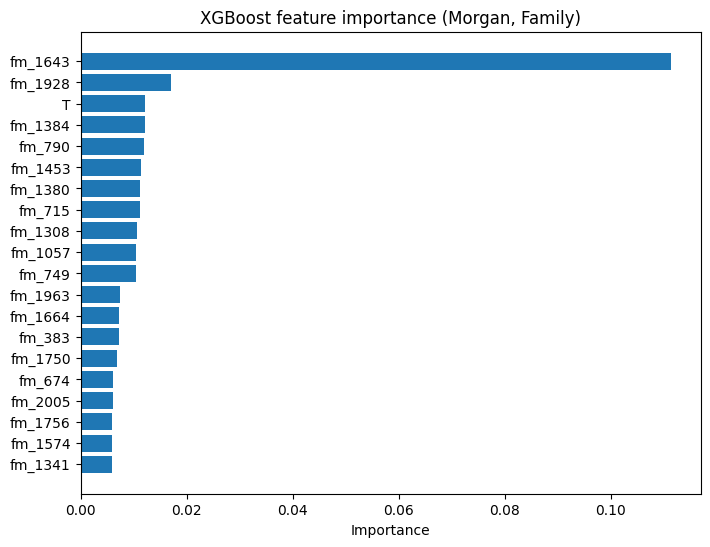

In [16]:
plot_importance('XGBoost')

### Multilayer perceptron

--- MLP | Descriptors | Butina split ---
best params: {'regressor__mlpregressor__activation': 'relu', 'regressor__mlpregressor__alpha': np.float64(0.015352246941973482), 'regressor__mlpregressor__hidden_layer_sizes': (50, 25), 'regressor__mlpregressor__learning_rate_init': np.float64(0.0036256176345762273)}
CV metrics per fold - MLP (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.243,2.086,0.906
2,3410.0,3.982,2.429,0.858
3,3419.0,4.697,2.640,0.831
4,3410.0,5.694,2.864,0.820
5,3409.0,5.767,2.966,0.765
mean,NaN,4.677,2.597,0.836
std,NaN,1.091,0.353,0.052


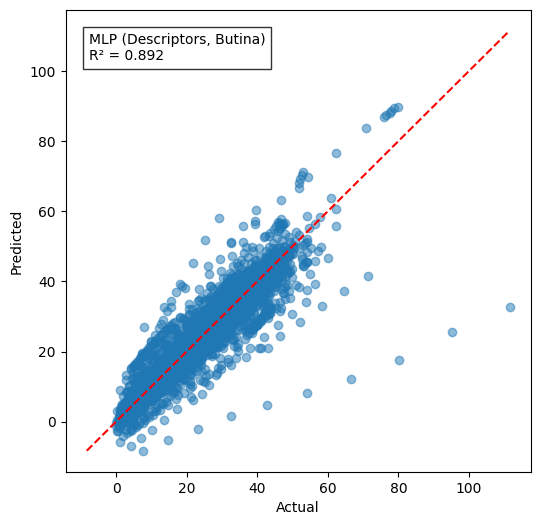

--- MLP | Descriptors | Family split ---
best params: {'regressor__mlpregressor__activation': 'relu', 'regressor__mlpregressor__alpha': np.float64(0.0027541439213320295), 'regressor__mlpregressor__hidden_layer_sizes': (50, 25), 'regressor__mlpregressor__learning_rate_init': np.float64(0.006586289317583112)}
CV metrics per fold - MLP (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,8.316,3.500,0.643
2,3421.0,3.783,2.331,0.883
3,3426.0,3.680,1.930,0.885
4,3410.0,3.823,2.339,0.877
5,3418.0,5.260,2.634,0.807
mean,NaN,4.972,2.547,0.819
std,NaN,1.979,0.589,0.104


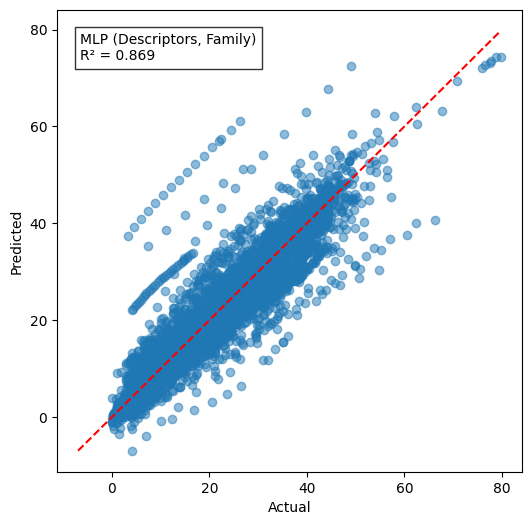

--- MLP | Morgan | Butina split ---


c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
1 fits failed out of a total of 40.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\base.py", line 1336, in wrap

best params: {'regressor__mlpregressor__activation': 'relu', 'regressor__mlpregressor__alpha': np.float64(0.015352246941973482), 'regressor__mlpregressor__hidden_layer_sizes': (50, 25), 'regressor__mlpregressor__learning_rate_init': np.float64(0.0036256176345762273)}
CV metrics per fold - MLP (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.746,2.610,0.874
2,3410.0,4.093,2.853,0.850
3,3419.0,4.920,3.142,0.815
4,3410.0,3.789,2.787,0.920
5,3409.0,5.721,3.292,0.768
mean,NaN,4.454,2.937,0.845
std,NaN,0.851,0.276,0.058


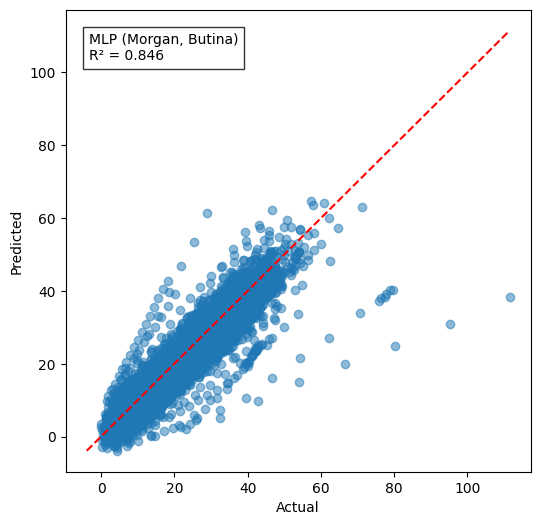

--- MLP | Morgan | Family split ---
best params: {'regressor__mlpregressor__activation': 'relu', 'regressor__mlpregressor__alpha': np.float64(0.015352246941973482), 'regressor__mlpregressor__hidden_layer_sizes': (50, 25), 'regressor__mlpregressor__learning_rate_init': np.float64(0.0036256176345762273)}
CV metrics per fold - MLP (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.746,3.100,0.884
2,3421.0,4.265,2.944,0.851
3,3426.0,4.534,2.991,0.825
4,3410.0,4.459,3.089,0.833
5,3418.0,5.348,3.312,0.801
mean,NaN,4.670,3.087,0.839
std,NaN,0.416,0.142,0.031


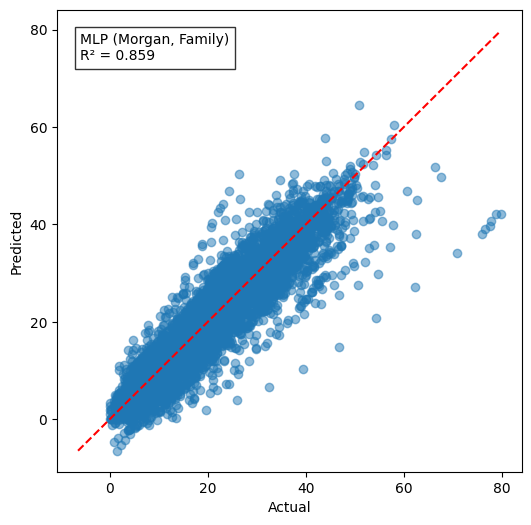

In [17]:
from sklearn.neural_network import MLPRegressor

params = {
    'regressor__mlpregressor__hidden_layer_sizes': [(50,), (100,), (50, 25), (100, 50), (50, 25, 10)],
    'regressor__mlpregressor__activation': ['relu', 'tanh'],
    'regressor__mlpregressor__alpha': loguniform(1e-5, 1e-1),
    'regressor__mlpregressor__learning_rate_init': loguniform(1e-4, 1e-2),
}
fit_all('MLP', lambda sc: scaled(MLPRegressor(max_iter=2000, early_stopping=True, n_iter_no_change=20,
                                              random_state=42), sc), params, n_iter=20)

### Multilayer Perceptron (PyTorch)

A from-scratch feedforward network (`TorchMLPRegressor` below) instead of `sklearn`'s `MLPRegressor`, giving explicit control over the regularization asked for:
- **Batch normalization** after every hidden `Linear` layer
- **Dropout** after each batch-norm/activation
- **Weight decay** (L2 penalty), via `Adam`'s `weight_decay`
- **Early stopping** on a held-out validation slice carved out of each fit's training data, restoring the best-validation-loss weights at the end of training, plotted below as loss and R² vs epoch (train and validation, with the best epoch marked)

It's wrapped as a scikit-learn estimator (`BaseEstimator`/`RegressorMixin`), so it plugs into the same `scaled(...)` / `fit_all(...)` machinery as the other models and lands in the same `metrics_<split>.pkl` tables for direct comparison, as `MLP_PyTorch` next to the existing sklearn `MLP`.

Caveats:
- The early-stopping validation slice is a plain random split, **not** grouped by `ChemID` like the outer CV/test splits - a practical simplification. It can share compounds with the rest of that fit's training data, so it's only meant to catch overfitting within a single fit, not to give a leakage-free estimate.
- PyTorch models don't parallelize well across `RandomizedSearchCV`'s worker processes (CPU oversubscription, or GPU context conflicts), so this search runs with `n_jobs=1` and will be the slowest cell in the notebook - doubly so here with two feature sets. Lower `n_iter` / `max_epochs` below if it's too slow, or set `device='cuda'` if you have a GPU.
- Needs `pip install torch` if it isn't already in this environment.

--- MLP_PyTorch | Descriptors | Butina split ---
best params: {'regressor__torchmlpregressor__dropout': np.float64(0.18727005942368125), 'regressor__torchmlpregressor__hidden_layer_sizes': (128, 64, 32), 'regressor__torchmlpregressor__lr': np.float64(0.00023273922280628724), 'regressor__torchmlpregressor__weight_decay': np.float64(0.0013145103232150123)}
CV metrics per fold - MLP_PyTorch (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.313,2.198,0.902
2,3410.0,3.147,1.933,0.911
3,3419.0,4.409,2.487,0.851
4,3410.0,5.659,2.960,0.822
5,3409.0,5.756,2.829,0.766
mean,NaN,4.457,2.481,0.850
std,NaN,1.241,0.427,0.060


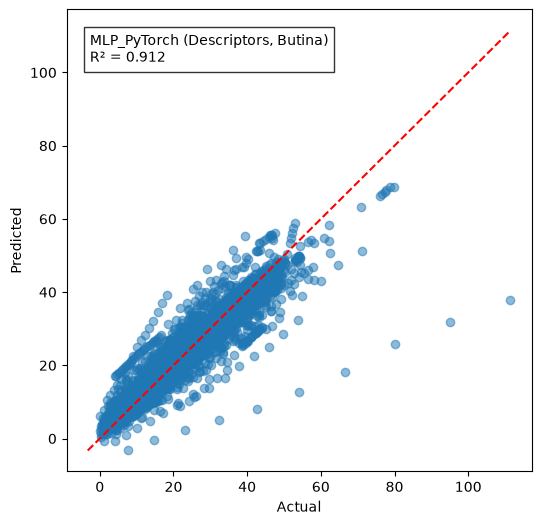

--- MLP_PyTorch | Descriptors | Family split ---
best params: {'regressor__torchmlpregressor__dropout': np.float64(0.21597250932105788), 'regressor__torchmlpregressor__hidden_layer_sizes': (32,), 'regressor__torchmlpregressor__lr': np.float64(0.0011208547084229376), 'regressor__torchmlpregressor__weight_decay': np.float64(3.9759772143180974e-05)}
CV metrics per fold - MLP_PyTorch (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,6.962,3.344,0.750
2,3421.0,4.316,2.487,0.847
3,3426.0,3.802,2.058,0.877
4,3410.0,3.518,2.129,0.896
5,3418.0,3.669,2.279,0.906
mean,NaN,4.453,2.460,0.855
std,NaN,1.434,0.521,0.063


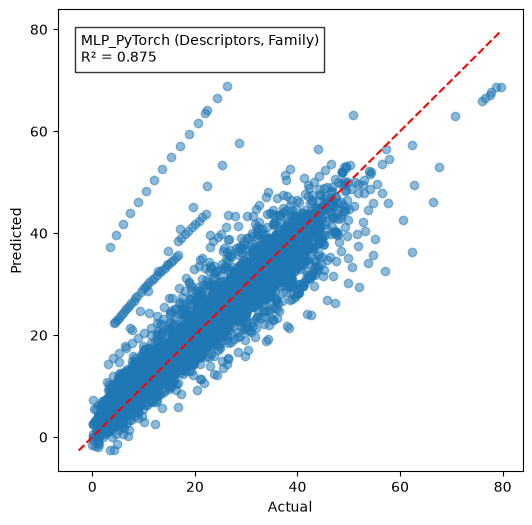

--- MLP_PyTorch | Morgan | Butina split ---
best params: {'regressor__torchmlpregressor__dropout': np.float64(0.028205789513550128), 'regressor__torchmlpregressor__hidden_layer_sizes': (128, 64), 'regressor__torchmlpregressor__lr': np.float64(0.007535384509295544), 'regressor__torchmlpregressor__weight_decay': np.float64(1.0071984838809197e-06)}
CV metrics per fold - MLP_PyTorch (Morgan, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.017,2.896,0.855
2,3410.0,4.055,2.876,0.853
3,3419.0,5.120,3.261,0.799
4,3410.0,3.843,2.756,0.918
5,3409.0,5.620,3.473,0.777
mean,NaN,4.531,3.053,0.840
std,NaN,0.790,0.302,0.055


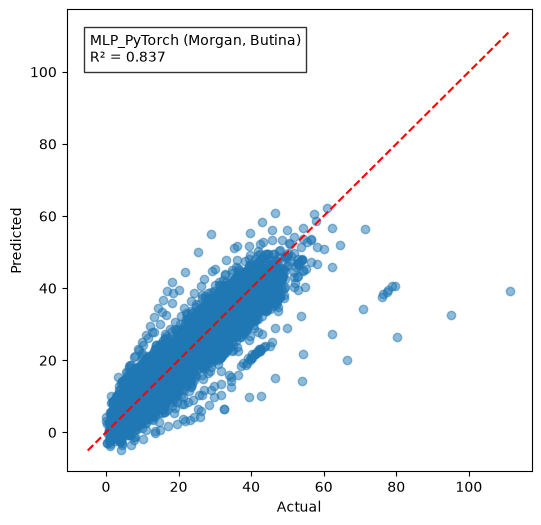

--- MLP_PyTorch | Morgan | Family split ---
best params: {'regressor__torchmlpregressor__dropout': np.float64(0.18727005942368125), 'regressor__torchmlpregressor__hidden_layer_sizes': (128, 64, 32), 'regressor__torchmlpregressor__lr': np.float64(0.00023273922280628724), 'regressor__torchmlpregressor__weight_decay': np.float64(0.0013145103232150123)}
CV metrics per fold - MLP_PyTorch (Morgan, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.959,3.428,0.873
2,3421.0,4.638,3.182,0.824
3,3426.0,4.701,3.115,0.812
4,3410.0,4.687,3.216,0.816
5,3418.0,5.393,3.458,0.798
mean,NaN,4.876,3.280,0.824
std,NaN,0.315,0.154,0.029


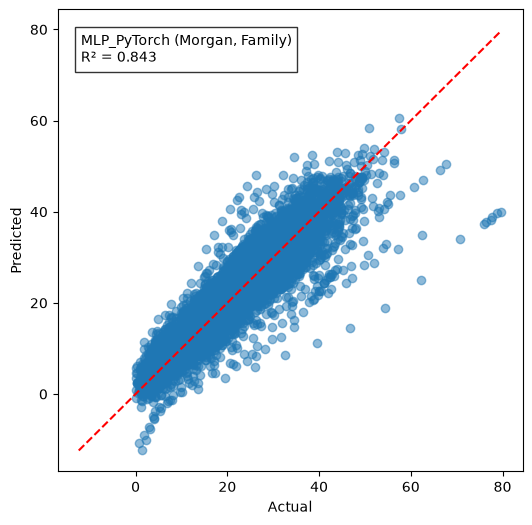

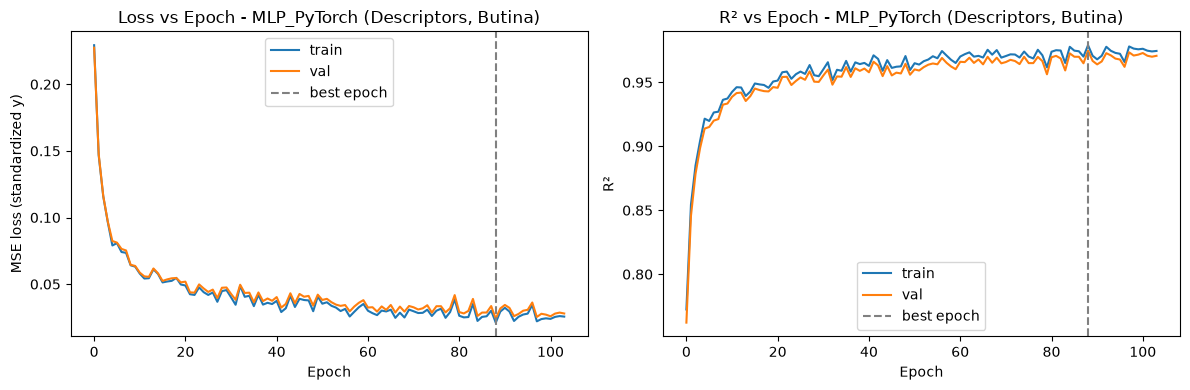

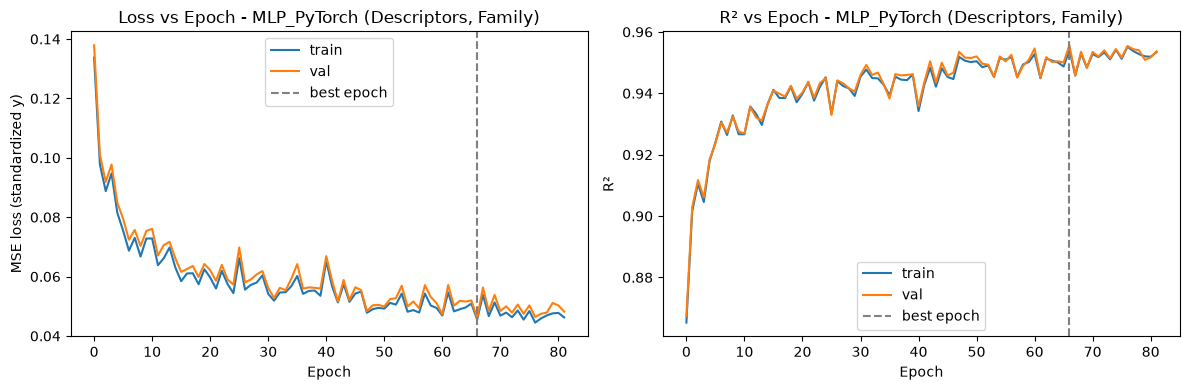

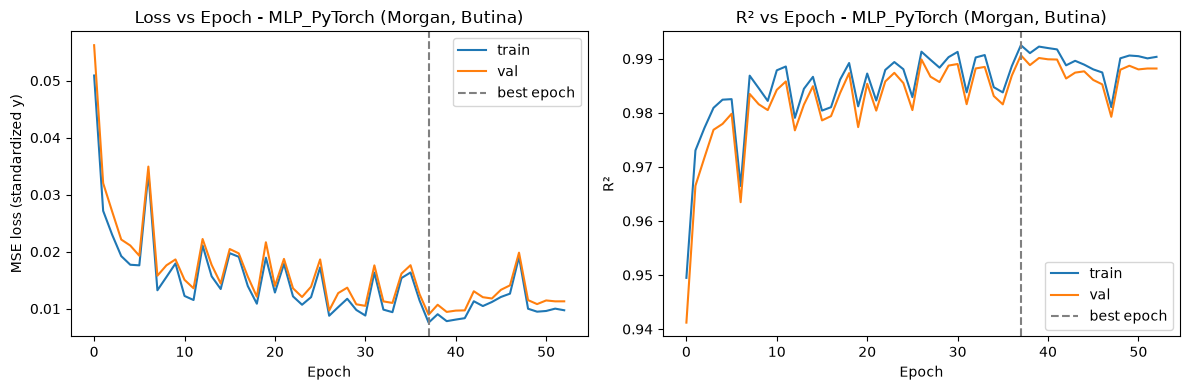

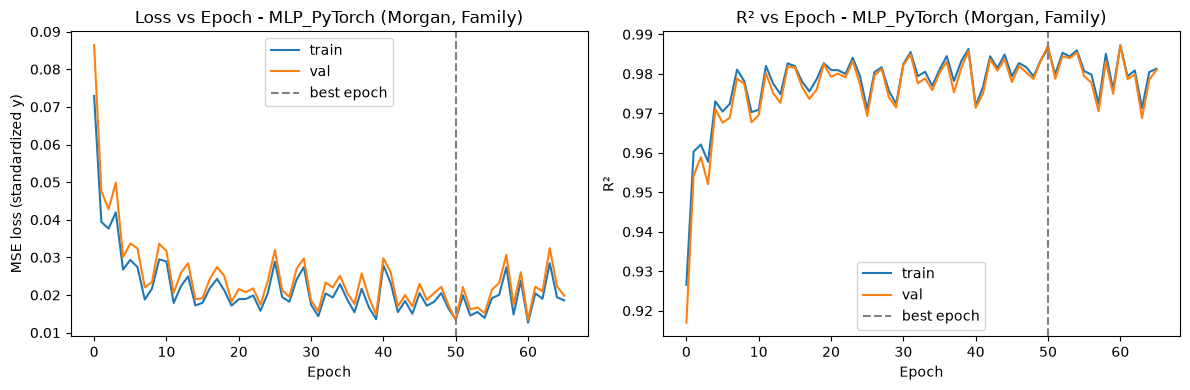

In [3]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.utils.validation import check_is_fitted


class TorchMLPRegressor(BaseEstimator, RegressorMixin):
    """[Linear -> BatchNorm -> ReLU -> Dropout] per hidden layer, then a linear output.
    Trained with Adam (weight_decay = L2) and early stopping on a held-out validation slice."""

    def __init__(self, hidden_layer_sizes=(64, 32), dropout=0.2, weight_decay=1e-4, lr=1e-3,
                 batch_size=64, max_epochs=200, patience=15, val_size=0.15, random_state=42, device=None):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.lr = lr
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_size = val_size
        self.random_state = random_state
        self.device = device

    def _build(self, n_features):
        device = self.device or ('cuda' if torch.cuda.is_available() else 'cpu')
        layers, in_dim = [], n_features
        for h in self.hidden_layer_sizes:
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(self.dropout)]
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        return nn.Sequential(*layers).to(device), device

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32).reshape(-1, 1)

        # Held out purely for early stopping - see the caveat above about ChemID grouping.
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=self.val_size,
                                                     random_state=self.random_state)

        self.model_, self.device_ = self._build(X.shape[1])
        opt = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.MSELoss()

        X_tr_t = torch.tensor(X_tr, device=self.device_)
        y_tr_t = torch.tensor(y_tr, device=self.device_)
        X_val_t = torch.tensor(X_val, device=self.device_)
        y_val_t = torch.tensor(y_val, device=self.device_)

        rng = np.random.default_rng(self.random_state)
        best_val, best_state, best_epoch, stall, epoch = np.inf, None, 0, 0, 0
        history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'train_r2': [], 'val_r2': []}

        for epoch in range(self.max_epochs):
            self.model_.train()
            perm = rng.permutation(len(X_tr_t))
            for start in range(0, len(perm), self.batch_size):
                idx = perm[start:start + self.batch_size]
                if len(idx) < 2:
                    continue   # BatchNorm needs >=2 samples per batch in train mode
                idx_t = torch.as_tensor(idx, dtype=torch.long, device=self.device_)
                opt.zero_grad()
                loss = loss_fn(self.model_(X_tr_t[idx_t]), y_tr_t[idx_t])
                loss.backward()
                opt.step()

            # full-batch eval, for the loss/R2-vs-epoch curves and the early-stopping check
            self.model_.eval()
            with torch.no_grad():
                train_pred = self.model_(X_tr_t)
                val_pred = self.model_(X_val_t)
                train_loss = loss_fn(train_pred, y_tr_t).item()
                val_loss = loss_fn(val_pred, y_val_t).item()

            history['epoch'].append(epoch)
            history['train_loss'].append(train_loss)
            history['val_loss'].append(val_loss)
            history['train_r2'].append(r2_score(y_tr, train_pred.cpu().numpy()))
            history['val_r2'].append(r2_score(y_val, val_pred.cpu().numpy()))

            if val_loss < best_val - 1e-6:
                best_val, best_epoch, stall = val_loss, epoch, 0
                best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
            else:
                stall += 1
            if stall >= self.patience:
                break

        self.model_.load_state_dict(best_state)
        self.n_epochs_, self.best_val_loss_, self.best_epoch_ = epoch + 1, best_val, best_epoch
        self.history_ = history
        return self

    def predict(self, X):
        check_is_fitted(self, 'model_')
        X = np.asarray(X, dtype=np.float32)
        self.model_.eval()
        with torch.no_grad():
            return self.model_(torch.tensor(X, device=self.device_)).cpu().numpy().ravel()


params = {
    'regressor__torchmlpregressor__hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)],
    'regressor__torchmlpregressor__dropout': uniform(0.0, 0.5),
    'regressor__torchmlpregressor__weight_decay': loguniform(1e-6, 1e-2),
    'regressor__torchmlpregressor__lr': loguniform(1e-4, 1e-2),
}
fit_all('MLP_PyTorch', lambda sc: scaled(TorchMLPRegressor(max_epochs=200, patience=15), sc),
        params, n_iter=10, n_jobs=1)

for fs in FSETS:
    for s in SPLITS:
        plot_training_curves('MLP_PyTorch', fs, s, f'MLP_PyTorch ({fs}, {s})')

In [6]:
for s in SPLITS:
    for fs, cols in FEATURES.items():
        check_tc_violations('MLP_PyTorch', split = s, fs= fs)

Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - MLP_PyTorch (Descriptors, Butina)


,T/TC >=,n_rows,n_violations
0,0.90,217,208
1,0.95,44,38
2,0.98,5,5
3,0.99,4,4


15 worst violations (closest to TC, by T/TC) - MLP_PyTorch (Descriptors, Butina)


,ChemID,Family,T,TC,actual,predicted,Tr
3856,1035,ALDEHYDES,554.14,554.00,4.451,3.246,1.000
2602,1275,OTHER ALIPHATIC ACIDS,694.00,694.00,0.000,2.056,1.000
2557,2801,ISOCYANATES/DIISOCYANATES,765.00,765.00,0.398,3.517,1.000
3862,5892,"POLYFUNCTIONAL C, H, O, N",589.00,590.00,0.092,6.091,0.998
1424,2628,"C, H, F COMPOUNDS",442.89,451.55,0.203,2.722,0.981
4730,1378,AROMATIC ESTERS,839.64,870.00,0.947,3.923,0.965
4346,9899,POLYFUNCTIONAL ESTERS,823.03,853.90,1.331,4.486,0.964
4523,1225,POLYOLS,779.31,809.70,1.518,5.674,0.962
4822,3334,GLYCERIDES,804.48,836.00,0.794,3.481,0.962
2556,2801,ISOCYANATES/DIISOCYANATES,735.96,765.00,2.900,4.686,0.962


Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - MLP_PyTorch (Morgan, Butina)


,T/TC >=,n_rows,n_violations
0,0.90,217,145
1,0.95,44,19
2,0.98,5,4
3,0.99,4,3


... (6 outputs left out)

Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - MLP_PyTorch (Morgan, Family)


,T/TC >=,n_rows,n_violations
0,0.90,217,183
1,0.95,44,31
2,0.98,8,6
3,0.99,5,3


15 worst violations (closest to TC, by T/TC) - MLP_PyTorch (Morgan, Family)


,ChemID,Family,T,TC,actual,predicted,Tr
5227,1032,ALDEHYDES,543.200,543.20,0.097,3.617,1.000
2763,1275,OTHER ALIPHATIC ACIDS,694.000,694.00,0.000,4.721,1.000
3966,5892,"POLYFUNCTIONAL C, H, O, N",589.000,590.00,0.092,5.723,0.998
2748,1435,"OTHER POLYFUNCTIONAL C, H, O",712.800,720.00,0.340,4.564,0.990
1436,2628,"C, H, F COMPOUNDS",442.890,451.55,0.203,6.231,0.981
1577,1101,N-ALCOHOLS,503.150,513.20,0.900,5.224,0.980
2747,1435,"OTHER POLYFUNCTIONAL C, H, O",696.670,720.00,1.190,5.559,0.968
4890,1380,AROMATIC ESTERS,786.480,817.00,0.989,3.733,0.963
4551,1225,POLYOLS,779.310,809.70,1.518,6.372,0.962
1568,1101,N-ALCOHOLS,493.150,513.20,2.100,5.799,0.961


# Model comparison

In [19]:
# CV (mean +- std over folds, best candidate) vs test-set RMSE. GaussianProcess has no CV.
for s in SPLITS:
    rows = []
    for (alg, fs, sp), f in cv_folds.items():
        if sp != s:
            continue
        m = metrics[s]
        test_rmse = m.loc[(m['algorithm'] == alg) & (m['description'] == fs), 'RMSE'].iloc[0]
        rows.append({'feature_set': fs, 'algorithm': alg, 'CV_RMSE_mean': f['RMSE'].mean(),
                     'CV_RMSE_std': f['RMSE'].std(), 'CV_r2_mean': f['r2'].mean(), 'test_RMSE': test_rmse})
    print(f'===== {s} split: CV vs test =====')
    display(pd.DataFrame(rows).sort_values('test_RMSE').round(3).reset_index(drop=True))

===== Butina split: CV vs test =====


,feature_set,algorithm,CV_RMSE_mean,CV_RMSE_std,CV_r2_mean,test_RMSE
0,Descriptors,MLP_PyTorch,4.472,1.245,0.849,3.343
1,Descriptors,XGBoost,3.714,0.444,0.895,3.483
2,Descriptors,GradientBoosting,3.679,0.506,0.897,3.525
3,Descriptors,SVR,5.121,1.987,0.800,3.623
4,Descriptors,MLP,4.677,1.091,0.836,3.687
5,Descriptors,RandomForest,3.961,0.518,0.880,3.828
6,Morgan,MLP,4.454,0.851,0.845,4.403
7,Morgan,GradientBoosting,4.456,0.752,0.845,4.463
8,Morgan,XGBoost,4.293,0.593,0.857,4.496
9,Morgan,SVR,4.347,0.651,0.854,4.504


===== Family split: CV vs test =====


,feature_set,algorithm,CV_RMSE_mean,CV_RMSE_std,CV_r2_mean,test_RMSE
0,Descriptors,XGBoost,3.679,0.300,0.899,3.560
1,Descriptors,RandomForest,3.955,0.356,0.882,3.627
2,Descriptors,MLP_PyTorch,4.504,1.321,0.853,3.756
3,Descriptors,GradientBoosting,3.767,0.354,0.895,3.816
4,Descriptors,MLP,4.972,1.979,0.819,3.914
5,Descriptors,SVR,4.862,1.753,0.828,4.049
6,Morgan,MLP,4.670,0.416,0.839,4.062
7,Morgan,XGBoost,4.695,0.421,0.838,4.135
8,Morgan,GradientBoosting,4.790,0.501,0.832,4.185
9,Morgan,SVR,4.575,0.272,0.845,4.322


In [20]:
# Test-set metrics of every feature set saved so far (GC rows appear if 03_Modeling has been run)
for s in SPLITS:
    print(f'===== {s} split =====')
    display(metrics[s].sort_values('RMSE').reset_index(drop=True).round(3))

===== Butina split =====


,description,algorithm,MSE,RMSE,MAE,SD_error,NRMSE_%,r2_score
0,Descriptors,MLP_PyTorch,11.172621,3.342547,1.953643,3.342645,15.170166,0.911501
1,Descriptors,XGBoost,12.13212,3.483119,1.971473,3.477951,15.808154,0.903901
2,Descriptors,GradientBoosting,12.422363,3.524537,1.960977,3.516391,15.99613,0.901602
3,Descriptors,SVR,13.1236,3.622651,2.012031,3.614743,16.441419,0.896047
4,GC,MLP_PyTorch,13.226527,3.636829,2.08657,3.626986,16.505767,0.895232
5,Descriptors,MLP,13.593887,3.686989,2.004373,3.681039,16.733417,0.892322
6,Descriptors,RandomForest,14.653414,3.827978,2.17021,3.817407,17.373296,0.88393
7,GC,MLP,14.814753,3.848994,2.167495,3.840811,17.468677,0.882652
8,GC,XGBoost,15.09246,3.884902,2.237017,3.876862,17.631645,0.880452
9,GC,RandomForest,16.050737,4.006337,2.384896,3.98643,18.182781,0.872861


===== Family split =====


,description,algorithm,MSE,RMSE,MAE,SD_error,NRMSE_%,r2_score
0,GC,MLP_PyTorch,11.498182,3.390897,2.157482,3.37111,15.499867,0.90185
1,Descriptors,XGBoost,12.673114,3.559932,2.03272,3.549482,16.272529,0.89182
2,Descriptors,RandomForest,13.155799,3.627092,2.159858,3.623848,16.579522,0.8877
3,GC,MLP,13.384342,3.658462,2.181232,3.647587,16.722912,0.885749
4,GC,XGBoost,13.737128,3.706363,2.253807,3.702378,16.941871,0.882738
5,Descriptors,MLP_PyTorch,14.108286,3.7561,2.111376,3.730603,17.169218,0.879569
6,Descriptors,GradientBoosting,14.562817,3.816126,2.176133,3.801668,17.443599,0.875689
7,GC,RandomForest,14.668975,3.83001,2.420258,3.828464,17.507062,0.874783
8,GC,GradientBoosting,14.738294,3.839049,2.316814,3.833018,17.548379,0.874191
9,Descriptors,MLP,15.323083,3.914471,2.188752,3.912758,17.893136,0.8692
